# COGS 108 - EDA Checkpoint

## Authors

Team list and credits:
- Keanu Ventura: Research Question, Background and Prior Work, Data Overview, Team Expectations
- Antony Munkhchuluun: Research Question, Timeline, EDA: Length of reviews, sentiment of reviews
- Raymond Luong: Research Question, Ethics
- Shouki Katsuyama: Research Question, Hypothesis, Data, Raw Data Processing and Cleaning, Writeup for Datasets, all analysis other than analysis by user groups


## Research Question

How do review behaviors, average review length, star rating, review frequency, and geographic diversity, differ among critical, generous, and neutral Google Maps users in California (up to Sep 2021), based on ratings of highly-rated or harshly-rated restaurants?

- "Highly-rated businesses" are defined as locations with at least 100 reviews and an average rating above 4.5, while "harshly-rated restaurants" have at least 100 reviews and an average rating below 3.5.
- Users with at least 100 reviews are considered; "critical users" are those who rated at least two highly-rated restaurants 1 or 2 stars, "generous users" are those who rated at least two harshly-rated restaurants 5 stars, and "neutral users" are all other users.

## Background and Prior Work

Online reviews play a significant role in consumers' decision-making process and a business's reputation, particularly on Google Maps. Users influence potential customers, search engine positioning, and, in some cases, whether a business thrives through ratings in the form of stars, written commentary, and even pictures they post. Although they pervade, there is still much to be discovered about the reviewers themselves, such as how different users behave across multiple reviews and whether certain users consistently deviate from the majority in recognizable ways. For this project, we will identify "critical," "generous," and "neutral" reviewers based on how their ratings compare to the average rating of the establishments they review. We will also determine whether these categories of reviewers exhibit distinct behavioral patterns.

Research has noted that online review distributions are highly polarized, with most users leaving extremely positive or extremely negative reviews, and proportionately fewer in between. This theory confirms that we can successfully categorize and recognize reviewers into at least two categories: critical and generous. Studies such as When Consistency Matters: The Effect of Valence Consistency on Review Helpfulness (Quaschning, Pandelaere & Vermeir, 2014) show that outlier reviews that don't match the mass opinion, i.e., a negative review for a well-rated business, are generally considered less credible or helpful, which means that reviewers that consistently deviate are likely to have recognizable traits rather than being single outlier reviews.These findings offer a solid foundation for characterizing reviewers as generous or critical and show that these differences are not noise but significant features of user behavior.<a name="cite_ref-1"></a>[<sup>1</sup>](#cite_note-1)

Prior research indicates that online review distributions are often polarized, with most users leaving extremely positive or extremely negative reviews and relatively few moderate ones (Quaschning, Pandelaere & Vermeir, 2014). This polarization supports the feasibility of categorizing reviewers into critical and generous types. For instance, Quaschning et al. (2014) found that reviews deviating from the consensus—such as negative reviews of highly rated establishments—are generally perceived as less helpful, suggesting that reviewers who consistently deviate have identifiable behavioral traits rather than being isolated outliers.<a name="cite_ref-2"></a>[<sup>2</sup>](#cite_note-2)

To supplement star ratings, the content of written reviews can provide a more insightful picture of the behavior of reviewers. The literature that currently exists in natural language processing (NLP) indicates that text analysis of reviews can reveal sentiment, prevailing themes, and behavioral tendencies of customers. For instance, the GitHub project NLP Sentiment Analysis with Yelp Review Data Set (dailyLi, 2019) employs machine learning models, such as convolutional and recurrent neural networks, for review polarity prediction (positive or negative) and keyword detection driving sentiment. Though this project is targeted at review-level polarity rather than user-level behavior, it demonstrates the potential to combine textual and numeric data for reviewer descriptions. Our research extends this strand of research by examining whether reviewer types—critical, generous, or neutral—exhibit stable patterns in both ratings and text content, including the proportion of reviews with photos or specific linguistic features.<a name="cite_ref-3"></a>[<sup>3</sup>](#cite_note-3)

One of our team members' prior work, Cooking Up Insights (Ventura, 2025), explored user behavior in recipe reviews, examining rating deviations, trends across multiple reviews, and relationships between review content and ratings. This prior experience informs our methodology for processing review data and measuring user-level behavioral metrics. Building on these methods, our current project systematically identifies reviewer types and analyzes differences across rating deviations, review frequency, text sentiment, and photo usage. While prior literature has examined review helpfulness, sentiment, and extremity bias, few studies analyze user-level behavior across multiple establishments. Our project fills this gap, providing a comprehensive characterization of reviewer types on Google Maps.<a name="cite_ref-4"></a>[<sup>4</sup>](#cite_note-4)

References:

1. <a name="cite_note-1"></a> [^](#cite_ref-1) Quaschning, M., Pandelaere, M., & Vermeir, I. (2014). When Consistency Matters: The Effect of Valence Consistency on Review Helpfulness. *Journal of Consumer Psychology*, 24(2), 136–145. https://academic.oup.com/jcmc/article/20/2/136/4067535  
2. <a name="cite_note-2"></a> [^](#cite_ref-2) Karaman, H. (2021). Online Review Solicitations Reduce Extremity Bias in Online Review Distributions and Increase Their Representativeness. *Management Science*, 67(7), 4420–4445. https://pubsonline.informs.org/doi/10.1287/mnsc.2020.3758  
3. <a name="cite_note-3"></a> [^](#cite_ref-3) dailyLi. (2019). NLP Sentiment Analysis with Yelp Review Data Set. GitHub. https://github.com/dailyLi/yelp_da
4. <a name="cite_note-4"></a> [^](#cite_ref-4) Ventura, K. (2025). Cooking Up Insights. GitHub. https://github.com/KeanuVentura/CookingUpInsights  



## Hypothesis


We hypothesize there are statistically significant difference between "critical users", "generous users" and "neutral users." Specifically,

- "critical users" has generally longer review length, lower average rating in general, and more frequent reviews than "neutral users".
- "generous users" has generally shorter review length, higher average rating in general, and less frequent reviews than "neutral users".
- "neutral users" is a controlled group to compare with so we do not make any assumptions or hypotheses on this group.

## Data

### Data Overview

- **Dataset #1**
  - **Dataset Name:** Google Local Data (California 10-core Reviews, 2021)
  - **Link to the dataset:** [UCSD Google Local Data](https://mcauleylab.ucsd.edu/public_datasets/gdrive/googlelocal/#subsets)
  - **Number of observations:** ~44,476,890 reviews
  - **Number of variables:** ~8 per review entry
  - **Description of the variables most relevant to this project:**
    - `user_id` – ID of the reviewer
    - `name` – name of the reviewer
    - `time` – timestamp of the review (Unix time)
    - `rating` – numeric star rating given by the user
    - `text` – written content of the review
    - `pics` – list of photos attached to the review
    - `resp` – business response including timestamp and text
    - `gmap_id` – ID of the business being reviewed
  - **Descriptions of any shortcomings this dataset has with respect to the project:**
    - Extremely large file size (~44M reviews) makes it difficult to load fully into memory
    - Some reviews may have missing fields (e.g., missing text or photos)
    - Data only goes up to September 2021, so recent trends are not captured
    - Ratings reflect both reviewer behavior and inherent bias

- **Dataset #2**
  - **Dataset Name:** Google Local Data (California Business Metadata, 2021)
  - **Link to the dataset:** [UCSD Google Local Data](https://mcauleylab.ucsd.edu/public_datasets/gdrive/googlelocal/#subsets)
  - **Number of observations:** 515,961 businesses
  - **Number of variables:** ~12–15 per business entry
  - **Description of the variables most relevant to this project:**
    - `name` – name of the business
    - `address` – business address
    - `gmap_id` – ID of the business
    - `description` – description of the business
    - `latitude` / `longitude` – location coordinates
    - `category` – business category/type
    - `avg_rating` – average rating of the business
    - `num_of_reviews` – total number of reviews
    - `price` – pricing information (e.g., $, $$, $$$)
    - `hours` – business open hours
    - `MISC` – additional business info (accessibility, payment options, etc.)
    - `state` – current status (e.g., permanently closed)
    - `relative_results` – related or recommended businesses
    - `url` – URL link to the business page
  - **Descriptions of any shortcomings this dataset has with respect to the project:**
    - Some businesses may have missing or incomplete metadata fields
    - Not all categories are evenly represented, which may affect analyses by category
    - Metadata only up to September 2021


## EDA

Import libraries and setup global variables.

In [1]:
import os
import datetime
import re
import json
import gzip
from functools import partial
import sys

import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import statsmodels.api as sm
import scipy

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from pyzipcode import ZipCodeDatabase
from wordcloud import WordCloud
from nltk.corpus import stopwords

sys.path.append("./modules/dataset")
from modules.dataset.get_data import get_raw

np.random.seed(0)

In [2]:
raw_path = "./data/00-raw"
interim_path = "./data/01-interim"
processed_path = "./data/02-processed"

meta_path = "./data/00-raw/meta-California.json.gz"
meta_keys = ["gmap_id", "name", "latitude", "longitude", "category", "avg_rating", "num_of_reviews", "address"]

review_path = "./data/00-raw/review-California.json.gz"
review_keys = ["gmap_id", "user_id", "name", "time", "rating", "text"]

total_reviews = 70529977

results_path = "./results"

palette = {"critical": "#a02121", "neutral": "#54d582", "generous": "#5497d5"}
order = ["critical", "neutral", "generous"]

analyzer = SentimentIntensityAnalyzer()

### Downloading Dataset

In [3]:
os.makedirs("./data/00-raw", exist_ok=True)
os.makedirs("./data/01-interim", exist_ok=True)
os.makedirs("./data/02-processed", exist_ok=True)

processed = os.path.exists(f"{processed_path}/neutral_user_reviews.csv")

In [4]:
datafiles = [
    { "url": "https://mcauleylab.ucsd.edu/public_datasets/gdrive/googlelocal/review-California.json.gz", "filename": "review-California.json.gz"},
    { "url": "https://mcauleylab.ucsd.edu/public_datasets/gdrive/googlelocal/meta-California.json.gz", "filename": "meta-California.json.gz"}
]

if not processed:
    get_raw(datafiles, destination_directory="data/00-raw/")

You need at leat 16GB of memory to run the following preprocesing.

In [5]:
def parse(path):
    g = gzip.open(path, 'r')
    for l in g:
        yield json.loads(l)

### Processing Business Data
Here, we process review data in the dataset.

In [6]:
def analyze_raw_categories():
    categories = []
    for business in parse(meta_path):
        if business["category"] is not None:
            categories += business["category"]

    categories = np.array(categories)
    unique, counts = np.unique(categories, return_counts=True)
    print(f"The number of unique categories is {unique.shape[0]}")

    top_categories = unique[np.argsort(counts)[::-1][:5]]
    print(f"Top 5 frequent categories are {' / '.join(top_categories)}")

    restaurant_categories = [category for category in unique if "restaurant" in category.lower()]
    print(f"The number of categories containting 'restaurant' substring is {len(restaurant_categories)}")

    with open(f"{interim_path}/restaurant_categories.txt", "w") as f:
        f.write("\n".join(restaurant_categories))

def filter_by_category(data, categories):
    category = data.get("category", None)
    if category is None:
        return False

    return len(set(category) & categories) != 0

def filter_by_num_reviews(data, min_num_reviews):
    return data["num_of_reviews"] >= min_num_reviews

def filter_by_avg_rating(data, rating_range):
    avg_rating = data["avg_rating"]
    return (rating_range[0] < avg_rating) & (avg_rating <= rating_range[1])

def filter_raw_business_data(filters):
    businesses = []
    for business in parse(meta_path):
        if all([f(data=business) for f in filters]):
            business = {key: business.get(key, None) for key in meta_keys}
            businesses.append(business)

    print(f"We obtained total of {len(businesses)} after filtering")

    df = pd.DataFrame(businesses)
    print(df.head())

    df = df.dropna()
    print(f"The number of restaurants after dropping business with missing entry is {df.shape[0]}")
    df.to_csv(f"{interim_path}/restaurants.csv", index=False)

def filter_business_data(restaurants, filters, name):
    print(restaurants.head())

    for f in filters:
        restaurants = restaurants[f(restaurants)]

    print(f"There are {restaurants.shape[0]} {name} after filering.")
    restaurants = restaurants.reset_index(drop=True)
    restaurants.to_csv(f"{interim_path}/{name}.csv", index=False)

First, we extract categories related to restaurants.

In [7]:
if not processed and not os.path.exists(f"{interim_path}/restaurant_categories.txt"):
    analyze_raw_categories()

Then, we filter business by categories extracted above.

In [8]:
if not processed and not os.path.exists(f"{interim_path}/restaurants.csv"):
    with open(f"{interim_path}/restaurant_categories.txt", "r") as f:
        restaurant_categories = set(f.read().split("\n"))

    min_num_reviews = 100
    restaurant_filter = partial(filter_by_category, categories=restaurant_categories)
    num_reviews_filter = partial(filter_by_num_reviews, min_num_reviews=min_num_reviews)

    filter_raw_business_data([restaurant_filter, num_reviews_filter])

Then, we split restaurants into three categories by their corresponding average rating range.

In [9]:
names = ["harshly", "highly"]
rating_ranges = [[0, 3.5], [4.5, 5.0]]

assert len(names) == len(rating_ranges)

for name, rating_range in zip(names, rating_ranges):
    if not processed and not os.path.exists(f"{interim_path}/{name}_rated_restaurants.csv"):
        restaurants = pd.read_csv(f"{interim_path}/restaurants.csv")
        filter = partial(filter_by_avg_rating, rating_range=rating_range)
        filter_business_data(restaurants, filters=[filter], name=f"{name}_rated_restaurants")

### Process Review Data
Here, we process review data in the dataset.

In [10]:
def filter_by_gmap_id(data, gmap_ids):
    gmap_id = data.get("gmap_id", None)
    if gmap_id is None:
        return False

    return gmap_id in gmap_ids

def filter_raw_review_data(filters):
    reviews = []
    for review in tqdm.tqdm(parse(review_path), total=total_reviews):
        if all([f(data=review) for f in filters]):
            review = {key: review.get(key, None) for key in review_keys}
            reviews.append(review)

    print(f"We obtained total of {len(reviews)} reviews after filtering")

    df = pd.DataFrame(reviews)
    print(df.head())

    print(f"The number of reviews before dropping reviews with missing entry is {df.shape[0]}")
    df = df.dropna().reset_index(drop=True)
    print(f"The number of reviews after dropping reviews with missing entry is {df.shape[0]}")
    print(df.isnull().sum())

    df.to_csv(f"{interim_path}/reviews.csv", index=False)

def extract_user_ids(reviews, min_num_reviews):
    user_ids = reviews["user_id"].values
    unique, counts = np.unique(np.array(user_ids), return_counts=True)
    users = pd.DataFrame({"user_id": unique, "num_reviews": counts})

    users = users[users["num_reviews"] >= min_num_reviews].reset_index(drop=True)
    print(f"We found {users.shape[0]} users in total.")
    users.to_csv(f"{interim_path}/users.csv", index=False)

def filter_by_user_ids(reviews, user_ids):
    reviews = reviews[reviews["user_id"].isin(user_ids)]
    reviews = reviews.dropna().reset_index(drop=True)
    print(f"We found {reviews.shape[0]} reviews assocaited with users we extracted.")
    reviews.to_csv(f"{interim_path}/user_reviews.csv", index=False)

First, we extract reviews which are associated with restaurants we extracted above.

In [11]:
if not processed and not os.path.exists(f"{interim_path}/reviews.csv"):
    gmap_ids = set(pd.read_csv(f"{interim_path}/restaurants.csv")["gmap_id"].values)
    gmap_id_filter = partial(filter_by_gmap_id, gmap_ids=gmap_ids)
    filter_raw_review_data([gmap_id_filter])

Then, we extract users who has at leat 10 reviews in above list of reviews.

In [12]:
if not processed and not os.path.exists(f"{interim_path}/users.csv"):
    print("Start processing user data")
    reviews = pd.read_csv(f"{interim_path}/reviews.csv")
    min_num_reviews = 10
    extract_user_ids(reviews, min_num_reviews)

Finally, we extract reviews which are associated with users we extracted above.

In [13]:
if not processed and not os.path.exists(f"{interim_path}/user_reviews.csv"):
    print("Start filtering review data")
    reviews = pd.read_csv(f"{interim_path}/reviews.csv")
    user_ids = pd.read_csv(f"{interim_path}/users.csv")["user_id"].values
    filter_by_user_ids(reviews, user_ids)

### Find User Groups
Here, we find user groups we defined in research question from the data we processed above.

In [14]:
def filter_reviews_by_grouped_restaurants(reviews, name):
    restaurants = pd.read_csv(f"{interim_path}/{name}_rated_restaurants.csv")
    gmap_ids = restaurants["gmap_id"].values
    reviews = reviews[reviews["gmap_id"].isin(gmap_ids)]

    print(f"We found {reviews.shape[0]} reviews for {name} rated restaurants")
    reviews = reviews.reset_index(drop=True)
    reviews.to_csv(f"{interim_path}/{name}_rated_restaurants_reviews.csv", index=False)

def find_critical_users(min_num_reviews):
    restaurants_reviews = pd.read_csv(f"{interim_path}/highly_rated_restaurants_reviews.csv")
    harsh_reviews = restaurants_reviews[restaurants_reviews["rating"].isin([1.0, 2.0])]

    user_ids = harsh_reviews["user_id"].values
    unique, counts = np.unique(np.array(user_ids), return_counts=True)

    critical_users = unique[counts >= min_num_reviews]
    print(f"We found {critical_users.shape[0]} critical users")

    with open(f"{interim_path}/critical_users.txt", "w") as f:
        f.write("\n".join(critical_users))

def find_generous_users(min_num_reviews):
    restaurants_reviews = pd.read_csv(f"{interim_path}/harshly_rated_restaurants_reviews.csv")
    generous_reviews = restaurants_reviews[restaurants_reviews["rating"].isin([5.0])]

    user_ids = generous_reviews["user_id"].values
    unique, counts = np.unique(np.array(user_ids), return_counts=True)

    generous_users = unique[counts >= min_num_reviews]
    print(f"We found {generous_users.shape[0]} generous users.")

    with open(f"{interim_path}/generous_users.txt", "w") as f:
        f.write("\n".join(generous_users))

def downsample_users():
    with open(f"{interim_path}/critical_users.txt", "r") as f:
        critical_users = f.read().split()

    with open(f"{interim_path}/generous_users.txt", "r") as f:
        generous_users = f.read().split()

    all_users = pd.read_csv(f"{interim_path}/users.csv")["user_id"].values
    neutral_users = [user for user in all_users if user not in list(critical_users) + list(generous_users)]

    intersection = [u for u in critical_users if u in generous_users]
    critical_users = [u for u in critical_users if u not in intersection]
    generous_users = [u for u in generous_users if u not in intersection]

    user_size = min(len(critical_users), len(generous_users))
    print(f"We have {user_size} users for each group.")

    critical_users = np.random.choice(critical_users, size=user_size, replace=False)
    generous_users = np.random.choice(generous_users, size=user_size, replace=False)
    neutral_users = np.random.choice(neutral_users, size=user_size, replace=False)

    assert len(critical_users) == len(generous_users) ==  len(neutral_users)
    intersection = [u for u in critical_users if u in generous_users]
    assert len(intersection) == 0

    reviews = pd.read_csv(f"{interim_path}/user_reviews.csv")

    critical_user_reviews = reviews[reviews["user_id"].isin(critical_users)]
    print(f"We found {critical_user_reviews.shape[0]} reviews by critical users.")
    critical_user_reviews.to_csv(f"{processed_path}/critical_user_reviews.csv", index=False)

    generous_user_reviews = reviews[reviews["user_id"].isin(generous_users)]
    print(f"We found {generous_user_reviews.shape[0]} reviews by generous users.")
    generous_user_reviews.to_csv(f"{processed_path}/generous_user_reviews.csv", index=False)

    neutral_user_reviews = reviews[reviews["user_id"].isin(neutral_users)]
    print(f"We found {neutral_user_reviews.shape[0]} reviews by neutral users.")
    neutral_user_reviews.to_csv(f"{processed_path}/neutral_user_reviews.csv", index=False)


First, we split reviews associated with harshly and highly rated restaurants.

In [15]:
names = ["harshly", "highly"]
for name in names:
    if not processed and not os.path.exists(f"{interim_path}/{name}_rated_restaurants_reviews.csv"):
        reviews = pd.read_csv(f"{interim_path}/user_reviews.csv")
        filter_reviews_by_grouped_restaurants(reviews, name)

Next, we find users who rated as least two bad/good reviews to highly/harshly rated restaurants as we defined in research question.

In [16]:
min_num_reviews = 2
if not processed and not os.path.exists(f"{interim_path}/critical_users.txt"):
    find_critical_users(min_num_reviews)

if not processed and not os.path.exists(f"{interim_path}/generous_users.txt"):
    find_generous_users(min_num_reviews)

Finally, we sample neutral users who does not belong to both of the groups, and downsample users to have same number of users in each group.

In [17]:
if not processed and not os.path.exists(f"{processed_path}/neutral_user_reviews.csv"):
    downsample_users()

### Loading Datasets

In [18]:
def load_user_reviews():
    critical = pd.read_csv(f"{processed_path}/critical_user_reviews.csv")
    generous = pd.read_csv(f"{processed_path}/generous_user_reviews.csv")
    neutral = pd.read_csv(f"{processed_path}/neutral_user_reviews.csv")

    return critical, generous, neutral

def load_combined_reviews():
    critical, generous, neutral = load_user_reviews()

    critical["group"] = critical["user_id"].apply(lambda x: "critical")
    generous["group"] = generous["user_id"].apply(lambda x: "generous")
    neutral["group"] = neutral["user_id"].apply(lambda x: "neutral")

    combined = pd.concat([critical, neutral, generous], axis=0)

    return combined

def load_stats():
    stats = pd.read_csv(f"{results_path}/stats.csv")
    return stats

In [19]:
combined = load_combined_reviews()
combined.head()

,gmap_id,user_id,name,time,rating,text,group
0,0x80c2b9518dc4f7e7:0xdfbf945567a04fe2,110411655962160480227,Parker G,1522712068439,5.0,I love Star Night! I had a magnificent birthd...,critical
1,0x80db13eac056ebd9:0x859327ac66c19926,103149477910988498561,Richele Arnoult,1442025189457,5.0,Come for the vegetable dishes. All the Vegetab...,critical
2,0x80db13eac056ebd9:0x859327ac66c19926,110272054282387860282,Russell D,1546834782044,5.0,Great restaurant/ bar in Idyllwild.\n\nKinda t...,critical
3,0x80db13eac056ebd9:0x859327ac66c19926,117856053314504268642,sherry weiner,1561867039398,1.0,Service outstanding\nMosquitos everywhere we h...,critical
4,0x80db13eac056ebd9:0x859327ac66c19926,106579531934834016047,SD Vava,1527857903818,5.0,"Good food, top service, amazing patio views",critical


### Overview Analysis

In [20]:
def plot_overall_rating_bar(combined, show=False):
    df = combined["rating"].value_counts()
    df = df.reset_index()

    sns.set_style("whitegrid")
    plt.title("Distribution of ratings of all reviews")
    plt.xlabel("Rating")
    plt.ylabel("The number of reviews")

    sns.barplot(df, x="rating", y="count", order=[1.0, 2.0, 3.0, 4.0, 5.0], alpha=0.8)
    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/overall", exist_ok=True)
        plt.savefig(f"{results_path}/overall/overall_rating.png")
        plt.close()

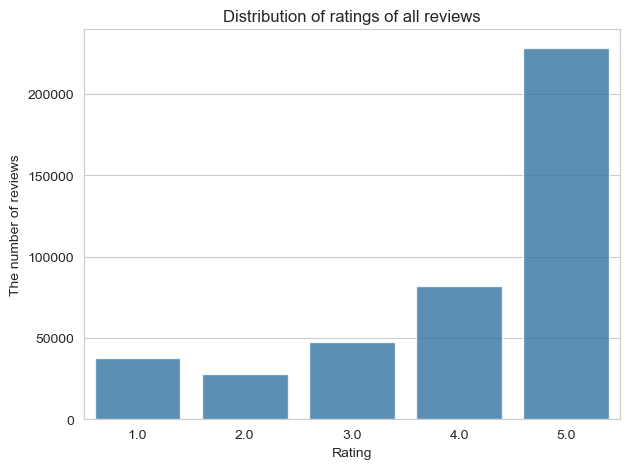

In [21]:
plot_overall_rating_bar(combined, show=True)

Due to our hypothesis that critical users and generous users have differences in review length, average rating, and frequency of reviews, it's important to visualize the baseline behavior of reviewers on Google. We chose this plot because it's important to see whether ratings overall are symmetric or polarized. This bar chart shows that the distribution of ratings are heavily skewed towards 5.0 with a small skew toward 1.0. This supports the basis of our hypothesis that online review distributions are polarized since people typically only leave reviews if they have strong opinions on the business. Moreover, because of the discreteness of the rating, some users are prone to appear as outliers such as those who give only 5 star reviews. These special cases are addressed further along in the EDA. 

In [22]:
def plot_overall_num_reviews_bar(combined, show=False):
    df = combined["group"].value_counts()
    df = df.reset_index()

    sns.set_style("whitegrid")
    plt.title("Total number of reviews by user groups")
    plt.xlabel("User groups")
    plt.ylabel("The number of reviews")

    sns.barplot(df, x="group", y="count", hue="group", order=order, palette=palette)
    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/overall", exist_ok=True)
        plt.savefig(f"{results_path}/overall/overall_num_reviews.png")
        plt.close()

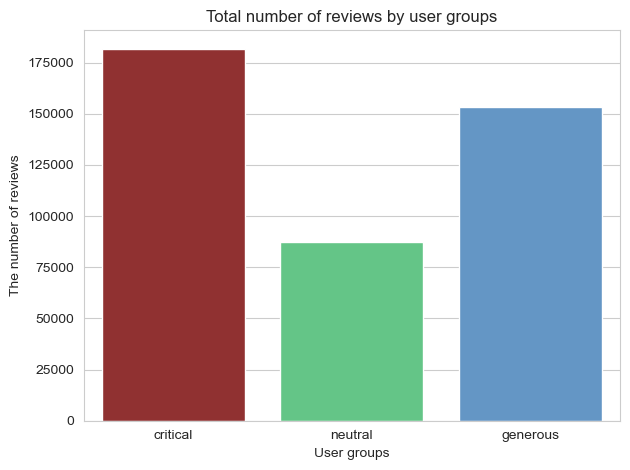

In [23]:
plot_overall_num_reviews_bar(combined, show=True)

We chose this plot here to compare how count of reviews depending on the user group they're in(critical, neutral, or generous). Since we have the same number of users for each group which is 4155, this represents how active each user group is. The results of the graph show that critical and generous users display more activity compared to neutral users. In other words, non-neutral users constitute a disproportionate share of the reviews in our dataset. The takeaway is that users who are typically disagree with the consensus(our critical and generous users) are actually also more engaged reviewers that aren't just occasional outliers. It supports our decision to analyze these groups discretely as they largely influence the ratings of businesses by how they rate and the frequency at which they do so. 

In [24]:
def plot_rating_all_five_users(combined, show=False):
    df = combined[["user_id", "group", "rating"]].groupby("user_id").agg({"group": "first", "rating": "mean"})
    df = df.reset_index()

    ratios = []
    avg_five_users = df[df["rating"] == 5.0]
    for name in order:
        ratio = np.sum(avg_five_users["group"] == name) / np.sum(df["group"] == name)
        ratios.append((name, ratio))

    df = pd.DataFrame(ratios, columns=["group", "ratio"])

    sns.set_style("whitegrid")
    plt.title("Proportion of users who rate all restaurants 5 by user group")
    plt.xlabel("User groups")
    plt.ylabel("Proportion of all five rating users")

    sns.barplot(df, x="group", y="ratio", hue="group", order=order, palette=palette)
    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/overall", exist_ok=True)
        plt.savefig(f"{results_path}/overall/all_five.png")
        plt.close()


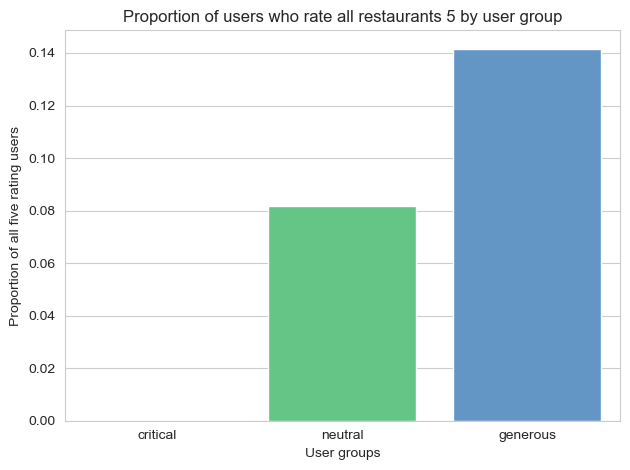

In [25]:
plot_rating_all_five_users(combined, show=True)

Before calculating statistics, we checked how many users give only 5 star ratings. These "all 5 star" rating users are important since they create zero variance in rating_std and represent a polarized form of generous behavior. Thus we chose this bar chart to represent it. Moreover, the data in the bar chart displays the proportion of users who has an average rating of exactly 5.0. Since we only include users with at least 10 star reviews, this means this is not a one off pattern but rather a reflection of consistent rating behavior. Highlighting these users show us our clear outliers for variance based metrics like rating_std which ends up being zero, affecting normality. The existence of these special groups also reinforce our hypothesis that there exists these specific group types of reviewers that affect reviewers of businesses as a whole rather than reviews simply being random deviations. 

### Calculating Statistics

In [26]:
def get_gmap_id_to_city():
    zcdb = ZipCodeDatabase()

    restaurants = pd.read_csv(f"{interim_path}/restaurants.csv")
    gmap2city = {}
    for gmap_id, address in restaurants[["gmap_id", "address"]].values:
        zipcode = address.split()[-1]
        try:
            city = zcdb[int(zipcode)].city
            gmap2city[gmap_id] = city
        except:
            gmap2city[gmap_id] = None

    return gmap2city

def convert_to_year_month(unix_time):
    dt = datetime.datetime.fromtimestamp(unix_time / 1000, datetime.timezone.utc)
    year = dt.year
    month = dt.month

    return f"{year}_{month}"

def convert_to_num(unix_time):
    dt = datetime.datetime.fromtimestamp(unix_time / 1000, datetime.timezone.utc)
    year = dt.year
    month = dt.month

    return f"{year}_{month}"

def get_text_length(text):
    return len(text.strip().split())

def get_sentiment(text):
    scores = analyzer.polarity_scores(text)
    return scores["compound"]

def get_diversity(text):
    tokens = text.lower().split()
    return len(tokens) / len(set(tokens))

We have a list of statistics for each user as follows:
- `rating_mean`: mean of ratings by a user, representing overall tendency of rating.
  
- `rating_std`: standard eviation of ratings by a user, representing how a user changes their rating for each restaurant.
  
- `num_reviews`: the number of reviews a user rated in total.
  
- `num_reviews_monthly_mean`: mean of the number of reviews a user rated per month, representing how active a user is given how a user is using Google Maps.
  
- `num_reviews_monthly_std`: standard deviation of the number of reviews a user rated per month, representing how much user changes their review frequency by month.
  
- `num_reviews_monthly_max`: maximum number of reviews a user rated per month, representing how much active a user was when a user was most active.
   
- `review_length_mean`: mean of review length in words, representing how long a user tend to write a review for each restaurant on average.
  
- `review_length_std`: standard deviation of review length in words, representing how a user changes length of their reviews for each restaurants.
  
- `num_cities`: the number of cities of restaurants a user has rated, representing how a user is active in terms of their geographical coverage.
  
- `sentiment_mean`: mean of component of nltk's sentiment analysis of user reviews, representing how positive user reviews are on average.

- `sentiment_std`: standard deviation of nltk's sentiment analysis of user reviews, representing how a user changes sentiment of their reviews for each restaurant.
  
- `activity_months`: the number of months a user rated at least one review, representing how long a user has been active.
  
- `activity_duration`: duration in terms of months between a user's first review and last review, representing how long a user has been using Google Maps including months a user was not active.
  
- `activity_rating_diff`: difference between mean of ratings for a user's first 10 reviews and last 10 reviews (last - first), representing how does a user changed rating from when a user started reviewing and a user is currently reviewing. (We may allow overlaps for such 10 reviews.)

- `diversity_mean`: mean of ratios of the number of unique words over the number of words in user reviews, representing how much a user use unique words in their reviews.
  
- `diversity_std`: standard deviation of ratios of the number of unique words over the number of words in user reviews, representing how much a user change word choice for each restaurants.

In [27]:
class Statistics():
    def __init__(self):
        combined = load_combined_reviews()
        self.user_ids = np.unique(combined["user_id"])
        user2group = {user_id: group for user_id, group in combined[["user_id", "group"]].values}
        self.groups = [user2group[user_id] for user_id in self.user_ids]

        gmap2city = get_gmap_id_to_city()

        combined["review_length"] = combined["text"].apply(get_text_length)
        combined["year_month"] = combined["time"].apply(convert_to_year_month)
        combined["city"] = combined["gmap_id"].apply(lambda x: gmap2city[x])
        combined["sentiment"] = combined["text"].apply(lambda x: get_sentiment(x))
        combined["diversity"] = combined["text"].apply(lambda x: get_diversity(x))

        self.combined = combined

    def get_rating_mean(self):
        df = self.combined[["user_id", "group", "rating"]].groupby("user_id").agg({"group": "first", "rating": "mean"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "rating"]].values}
        return user2stats

    def get_rating_std(self):
        df = self.combined[["user_id", "group", "rating"]].groupby("user_id").agg({"group": "first", "rating": "std"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "rating"]].values}
        return user2stats

    def get_num_reviews(self):
        df = self.combined[["user_id", "group"]].groupby("user_id").agg(["first", "count"])
        df = df.reset_index()
        df.columns = ["user_id", "group", "num_reviews"]

        user2stats = {user:stat for user, stat in df[["user_id", "num_reviews"]].values}
        return user2stats

    def get_num_reviews_monthly_mean(self):
        df = self.combined[["user_id", "group", "year_month"]].groupby(["user_id", "year_month"]).agg(["first", "count"])
        df = df.reset_index()
        df.columns = ["user_id", "year_month", "group", "num_reviews"]

        df = df.groupby("user_id").agg({"group": "first", "num_reviews": "mean"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "num_reviews"]].values}
        return user2stats

    def get_num_reviews_monthly_std(self):
        df = self.combined[["user_id", "group", "year_month"]].groupby(["user_id", "year_month"]).agg(["first", "count"])
        df = df.reset_index()
        df.columns = ["user_id", "year_month", "group", "num_reviews"]

        df = df.groupby("user_id").agg({"group": "first", "num_reviews": "std"})
        df = df.reset_index().fillna(0.0)

        user2stats = {user:stat for user, stat in df[["user_id", "num_reviews"]].values}
        return user2stats

    def get_num_reviews_monthly_max(self):
        df = self.combined[["user_id", "group", "year_month"]].groupby(["user_id", "year_month"]).agg(["first", "count"])
        df = df.reset_index()
        df.columns = ["user_id", "year_month", "group", "num_reviews"]

        df = df.groupby("user_id").agg({"group": "first", "num_reviews": "max"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "num_reviews"]].values}
        return user2stats

    def get_review_length_mean(self):
        df = self.combined[["user_id", "group", "review_length"]].groupby("user_id").agg({"group": "first", "review_length": "mean"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "review_length"]].values}
        return user2stats

    def get_review_length_std(self):
        df = self.combined[["user_id", "group", "review_length"]].groupby("user_id").agg({"group": "first", "review_length": "std"})
        df = df.reset_index()

        user2stats = {user:stat for user, stat in df[["user_id", "review_length"]].values}
        return user2stats

    def get_num_cities(self):
        df = self.combined[["user_id", "group", "city"]]
        df = df.groupby("user_id").agg({"group": "first", "city": "nunique"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "num_cities"]

        user2stats = {user:stat for user, stat in df[["user_id", "num_cities"]].values}
        return user2stats

    def get_sentiment_mean(self):
        df = self.combined[["user_id", "group", "sentiment"]]
        df = df.groupby("user_id").agg({"group": "first", "sentiment": "mean"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "sentiment"]

        user2stats = {user:stat for user, stat in df[["user_id", "sentiment"]].values}
        return user2stats

    def get_sentiment_std(self):
        df = self.combined[["user_id", "group", "sentiment"]]
        df = df.groupby("user_id").agg({"group": "first", "sentiment": "std"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "sentiment"]

        user2stats = {user:stat for user, stat in df[["user_id", "sentiment"]].values}
        return user2stats

    def get_activity_months(self):
        df = self.combined[["user_id", "group", "year_month"]]
        df = df.groupby("user_id").agg({"group": "first", "year_month": "nunique"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "activity"]

        user2stats = {user:stat for user, stat in df[["user_id", "activity"]].values}
        return user2stats

    def get_activity_duration(self):
        unix_month = 2629743 * 1000
        df = self.combined[["user_id", "group", "time"]]
        df = df.groupby("user_id").agg({"group": "first", "time": ["max", "min"]})
        df = df.reset_index()
        df.columns = ["user_id", "group", "max", "min"]
        df["activity"] = (df["max"] - df["min"]) / unix_month

        user2stats = {user:stat for user, stat in df[["user_id", "activity"]].values}
        return user2stats

    def get_activity_rating_diff(self):
        df = self.combined[["user_id", "group", "time", "rating"]]
        df = df.sort_values(by="time")
        df = df[["user_id", "group", "rating", "time"]]
        df = df.groupby("user_id").agg({
            "group": "first",
            "rating": [lambda x: x.head(10).mean(), lambda x: x.tail(10).mean()]
        })

        df = df.reset_index()
        df.columns = ["user_id", "group", "first", "last"]
        df["activity"] = df["last"] - df["first"]

        user2stats = {user:stat for user, stat in df[["user_id", "activity"]].values}
        return user2stats

    def get_diversity_mean(self):
        df = self.combined[["user_id", "group", "diversity"]]
        df = df.groupby("user_id").agg({"group": "first", "diversity": "mean"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "diversity"]

        user2stats = {user:stat for user, stat in df[["user_id", "diversity"]].values}
        return user2stats

    def get_diversity_std(self):
        df = self.combined[["user_id", "group", "diversity"]]
        df = df.groupby("user_id").agg({"group": "first", "diversity": "std"})
        df = df.reset_index()
        df.columns = ["user_id", "group", "diversity"]

        user2stats = {user:stat for user, stat in df[["user_id", "diversity"]].values}
        return user2stats

    def save_stats(self):
        with open(f"{results_path}/stats.txt", "r") as f:
            stats_list = f.read().split()

        results = {"user_id": list(self.user_ids), "group": list(self.groups)}
        for stats in stats_list:
            print(f"Processing {stats} statistics")
            method_name = f"get_{stats}"
            mapping = getattr(self, method_name)()
            results[stats] = [mapping[user_id] for user_id in self.user_ids]

        results = pd.DataFrame(results)
        print(results.head(5))

        results.to_csv(f"{results_path}/stats.csv", index=False)

In [28]:
if not os.path.exists(f"{results_path}/stats.csv"):
    statistics = Statistics()
    statistics.save_stats()

stats = load_stats()

### Helper Functions for Plotting

In [29]:
def plot_distribution(config, show=False):
    file_name = f"{results_path}/distribution/{config["name"]}.png"
    if not show and os.path.exists(file_name):
        return

    fig = plt.figure(figsize=(25, 12.5))
    gs = gridspec.GridSpec(2, 4)

    ax1 = fig.add_subplot(gs[0, 0])
    plot_bar(ax1, config["stats"], config["name"], config["desc"])

    ax2 = fig.add_subplot(gs[0, 1])
    plot_qq(ax2, config["stats"], config["name"], config["desc"])

    ax3 = fig.add_subplot(gs[1, 0])
    plot_box(ax3, config["filtered_stats"], config["name"], config["desc"],
            opt_desc=config.get("opt_desc", None))

    ax4 = fig.add_subplot(gs[1, 1])
    plot_violin(ax4, config["filtered_stats"], config["name"], config["desc"],
            opt_desc=config.get("opt_desc", None))

    ax5 = fig.add_subplot(gs[:, 2:])
    plot_hist(ax5, config["filtered_stats"], config["name"], config["desc"],
            bins=config["bins"], opt_desc=config.get("opt_desc", None))

    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/distribution", exist_ok=True)
        plt.savefig(file_name)
        plt.close()

def apply_transform(stats, transform):
    if transform == "log":
        stats = stats - np.min(stats) + 0.1
        return np.log(stats)
    elif transform == "reciprocal":
        stats = stats - np.min(stats) + 1
        return 1 / stats
    elif transform == "sqrt":
        stats = stats - np.min(stats) + 0.1
        return np.sqrt(stats / np.std(stats[stats != None]))
    elif transform == "cbrt":
        stats = stats - np.min(stats) + 0.1
        return np.cbrt(stats)
    elif transform == "outlier":
        return stats
    else:
        raise NotImplementedError

def remove_outliears(stats, name):
    origin_size = stats.shape[0]

    if name == "rating_std":
        stats = stats[stats[name] != 0.0]

    else:
        stats = stats[np.abs(scipy.stats.zscore(stats[name])) < 3]

    num_dropped = origin_size - stats.shape[0]
    if num_dropped > 0:
        print(f"    {origin_size - stats.shape[0]} outliers out of {origin_size} users are dropped.")

    return stats

def plot_transform(config, show):
    name = config["name"]
    new_name = f"{config["name"]}_{config["transform"]}"

    file_name = f"{results_path}/transform/{name}/{new_name}.png"
    if not show and os.path.exists(file_name):
        return

    fig = plt.figure(figsize=(25, 12.5))
    gs = gridspec.GridSpec(2, 4)

    transformation = partial(apply_transform, transform=config["transform"])

    stats = config["stats"].dropna(subset=name)
    stats = remove_outliears(stats, name)
    new_stats = pd.DataFrame({new_name: transformation(stats[name].values)})
    stats = pd.concat([stats, new_stats], axis=1)

    config["opt_desc"] = None
    min_bin, max_bin = np.min(stats[[new_name]]), np.max(stats[new_name])
    new_bins = np.linspace(min_bin, max_bin, 100)
    config["bins"] = new_bins

    desc = config["desc"]
    desc = f"{config["transform"].replace("_", " ")} of {desc}"

    ax1 = fig.add_subplot(gs[0, 0])
    plot_bar(ax1, stats, new_name, desc)

    ax2 = fig.add_subplot(gs[0, 1])
    plot_qq(ax2, stats, new_name, desc)

    ax3 = fig.add_subplot(gs[1, 0])
    plot_box(ax3, stats, new_name, desc,
            opt_desc=config.get("opt_desc", None))

    ax4 = fig.add_subplot(gs[1, 1])
    plot_violin(ax4, stats, new_name, desc,
            opt_desc=config.get("opt_desc", None))

    ax5 = fig.add_subplot(gs[:, 2:])
    plot_hist(ax5, stats, new_name, desc,
            bins=config["bins"], opt_desc=config.get("opt_desc", None))

    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/transform/{name}", exist_ok=True)
        plt.savefig(file_name)
        plt.close()

def plot_pair(config, show):
    file_name = f"{results_path}/pair/{config["name_x"]}_{config["name_y"]}.png"
    if not show and os.path.exists(file_name):
        return

    fig = plt.figure(figsize=(25, 12.5))
    gs = gridspec.GridSpec(2, 4)

    stats = config["stats"]
    stats["ratio"] = stats[config["name_y"]] / stats[config["name_x"]]

    desc_x, desc_y = config["desc_x"], config["desc_y"]
    name_x, name_y = config["name_x"], config["name_y"]
    ratio_desc = f"ratio of {desc_y}\nover {desc_x}"

    ax1 = fig.add_subplot(gs[0, 0])
    plot_bar(ax1, stats, "ratio", ratio_desc)

    ratio_range = config["ratio_range"]
    if ratio_range is not None:
        stats = stats[np.logical_and(stats["ratio"] >= ratio_range[0], stats["ratio"] <= ratio_range[1])]

    ax2 = fig.add_subplot(gs[0, 1])
    plot_hist(ax2, stats, "ratio", ratio_desc,
            bins=config["bins"], opt_desc=config.get("opt_ratio_desc", None))

    ax3 = fig.add_subplot(gs[1, 0])
    plot_box(ax3, stats, "ratio", ratio_desc,
            opt_desc=config.get("opt_ratio_desc", None))

    ax4 = fig.add_subplot(gs[1, 1])
    plot_violin(ax4, stats, "ratio", ratio_desc,
            opt_desc=config.get("opt_ratio_desc", None))

    ax5 = fig.add_subplot(gs[:, 2:])
    plot_scatter(ax5, config["filtered_stats"], name_x, name_y, desc_x, desc_y,
            opt_desc=config.get("opt_scatter_desc", None))

    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/pair", exist_ok=True)
        plt.savefig(file_name)
        plt.close()

def plot_bar(ax, stats, name, desc):
    sns.set_style("whitegrid")

    ax.set_title(f"Bar plot of {desc} by user groups")
    ax.set_xlabel("User groups")
    ax.set_ylabel(desc)

    sns.barplot(
        stats, x="group", y=name, ax=ax,
        hue="group", order=order, palette=palette, alpha=0.8)

def plot_hist(ax, stats, name, desc, bins, opt_desc):
    sns.set_style("whitegrid")

    if opt_desc is None:
        ax.set_title(f"Histogram of {desc} by user groups")
    else:
        ax.set_title(f"Histogram of {desc} by user groups\n({opt_desc})")

    ax.set_xlabel(desc)
    ax.set_ylabel("Frequenty")

    for group in reversed(order):
        sns.histplot(
            stats[stats["group"] == group], x=name, ax=ax,
            color=palette[group], alpha=0.5, label=group, bins=bins)

    ax.legend()

def plot_box(ax, stats, name, desc, opt_desc):
    sns.set_style("whitegrid")

    if opt_desc is None:
        ax.set_title(f"Box plot of {desc} by user groups")
    else:
        ax.set_title(f"Box plot of {desc} by user groups\n({opt_desc})")

    ax.set_xlabel("User groups")
    ax.set_ylabel(desc)

    sns.boxplot(
        stats, x="group", y=name, ax=ax,
        hue="group", order=order, palette=palette)

def plot_violin(ax, stats, name, desc, opt_desc):
    sns.set_style("whitegrid")

    if opt_desc is None:
        ax.set_title(f"Violin plot of {desc} by user groups")
    else:
        ax.set_title(f"Violin plot of {desc} by user groups\n({opt_desc})")

    ax.set_xlabel("User groups")
    ax.set_ylabel(desc)

    sns.violinplot(
        stats, x="group", y=name, ax=ax,
        hue="group", order=order, palette=palette, alpha=0.8)

def plot_qq(ax, stats, name, desc):
    sns.set_style("whitegrid")

    ax.set_title(f"Violin plot of {desc} by user groups")
    ax.set_xlabel(f"Quantiles of {desc}")
    ax.set_ylabel("Quantiles of standard normal")

    for group in order:
        group_stats = stats[stats["group"] == group][name].dropna().values
        group_stats = (group_stats - np.mean(group_stats)) / np.std(group_stats)

        sm.qqplot(group_stats, line="s", ax=ax, label=group,
                  markerfacecolor=palette[group], markeredgecolor=palette[group],
                  markersize=3, alpha=0.8)

    for i in range(6):
        ax.get_lines()[i].set_color("black")
    ax.legend()

def plot_scatter(ax, stats, name_x, name_y, desc_x, desc_y, opt_desc):
    sns.set_style("whitegrid")

    if opt_desc is None:
        ax.set_title(f"Scatter plot of {desc_x} and {desc_y} by user groups")
    else:
        ax.set_title(f"Scatter plot of {desc_x} and {desc_y} by user groups\n({opt_desc})")

    ax.set_xlabel(desc_x)
    ax.set_ylabel(desc_y)

    sns.scatterplot(stats, x=name_x, y=name_y, hue="group", style="group", palette=palette)

### Visualization of Distribution of Statistics

In [30]:
class DistributionVisualizer():
    def __init__(self, stats):
        self.stats = stats
        self.num_bins = 100

    def plot_activity_months(self):
        filtered_stats = self.stats[self.stats["activity_months"] <= 50]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "activity_months",
            "desc": "number of activity months",
            "bins": np.arange(50),
            "opt_desc": "excluded users whose number of activity months is larger than 50."
        }

        return config

    def plot_activity_duration(self):
        filtered_stats = self.stats[self.stats["activity_duration"] <= 100]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "activity_duration",
            "desc": "length of activity duration (months)",
            "bins": np.linspace(0, 100, self.num_bins),
            "opt_desc": "excluded users whose number of activity duration (months) is longer than 100."
        }

        return config

    def plot_activity_rating_diff(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "activity_rating_diff",
            "desc": "difference of ratings between first and last 10 reviews (last - first)",
            "bins": np.linspace(-4, 4, self.num_bins),
            "opt_desc": None
        }

        return config

    def plot_diversity_mean(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "diversity_mean",
            "desc": "mean of diversity of user reviews",
            "bins": np.linspace(1.0, 1.5, self.num_bins),
            "opt_desc": None
        }

        return config

    def plot_diversity_std(self):
        filtered_stats = self.stats[self.stats["diversity_std"] <= 0.5]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "diversity_std",
            "desc": "std of diversity of user reviews",
            "bins": np.linspace(0, 0.5, 50),
            "opt_desc": "excluded users whose std of diversity of review words is larger than 0.5."
        }

        return config

    def plot_num_cities(self):
        filtered_stats = self.stats[self.stats["num_cities"] <= 50]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "num_cities",
            "desc": "number of cities of user ratings",
            "bins": np.arange(50),
            "opt_desc": "excluded users whose number of cities is larger than 50."
        }

        return config

    def plot_num_reviews(self):
        filtered_stats = self.stats[self.stats["num_reviews"] <= 100]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "num_reviews",
            "desc": "number of user ratings",
            "bins": np.arange(10, 100),
            "opt_desc": "excluded users with more than 100 reviews"
        }

        return config

    def plot_num_reviews_monthly_mean(self):
        filtered_stats = self.stats[self.stats["num_reviews_monthly_mean"] <= 10]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "num_reviews_monthly_mean",
            "desc": "mean of numbers of user ratings per month",
            "bins": np.linspace(0, 10, self.num_bins),
            "opt_desc": "excluded users whose mean of reviews per month is larger than 10."
        }

        return config

    def plot_num_reviews_monthly_std(self):
        filtered_stats = self.stats[self.stats["num_reviews_monthly_std"] <= 10]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "num_reviews_monthly_std",
            "desc": "std of numbers of user ratings per month",
            "bins": np.linspace(0, 10, self.num_bins),
            "opt_desc": "excluded users whose std of reviews per month is larger than 10."
        }

        return config

    def plot_num_reviews_monthly_max(self):
        filtered_stats = self.stats[self.stats["num_reviews_monthly_max"] <= 30]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "num_reviews_monthly_max",
            "desc": "max of numbers of user ratings per month",
            "bins": np.arange(0, 30),
            "opt_desc": "excluded users whose max of reviews per month is larger than 30."
        }

        return config


    def plot_rating_mean(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "rating_mean",
            "desc": "mean of user ratings",
            "bins": np.linspace(1.0, 5.0, self.num_bins),
        }

        return config

    def plot_rating_std(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "rating_std",
            "desc": "std of user ratings",
            "bins": np.linspace(0, 2.5, self.num_bins),
        }

        return config

    def plot_review_length_mean(self):
        filtered_stats = self.stats[self.stats["review_length_mean"] <= 100]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "review_length_mean",
            "desc": "mean of review lengths of user ratings",
            "bins": np.linspace(0, 100, self.num_bins),
            "opt_desc": "excluded users whose mean of review lengths is larger than 100."
        }

        return config

    def plot_review_length_std(self):
        filtered_stats = self.stats[self.stats["review_length_std"] <= 100]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name": "review_length_std",
            "desc": "std of review lengths of user ratings",
            "bins": np.linspace(0, 100, self.num_bins),
            "opt_desc": "excluded users whose std of review lengths is larger than 100."
        }

        return config

    def plot_sentiment_mean(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "sentiment_mean",
            "desc": "mean of sentiment of user reviews",
            "bins": np.linspace(-1, 1, self.num_bins),
            "opt_desc": None
        }

        return config

    def plot_sentiment_std(self):
        config = {
            "stats": self.stats,
            "filtered_stats": self.stats,
            "name": "sentiment_std",
            "desc": "std of sentiment of user reviews",
            "bins": np.linspace(0, 1.0, self.num_bins),
            "opt_desc": None
        }

        return config

    def plot_stats(self, name, transform=None, show=False):
        method_name = f"plot_{name}"
        config = getattr(self, method_name)()

        if transform is not None:
            config["transform"] = transform
            plot_transform(config, show)

        else:
            plot_distribution(config, show)

    def plot_all_stats(self):
        with open(f"{results_path}/stats.txt", "r") as f:
            stats_list = f.read().split()

        for stats in stats_list:
            print(f"Plotting {stats} statistics")
            self.plot_stats(stats)

    def plot_all_stats_transform(self):
        with open(f"{results_path}/stats.txt", "r") as f:
            stats_list = f.read().split()

        with open(f"{results_path}/manual_distribution.json", "r") as f:
            dist = json.load(f)

        for stats in stats_list:
            stat_dist = dist[stats]
            if stat_dist["normal"] == 0:
                for transform in ["outlier", "log", "reciprocal", "sqrt", "cbrt"]:
                    print(f"Plotting {stats} statistics with {transform} transform")
                    self.plot_stats(stats, transform=transform)


In [31]:
distribution_visualizer = DistributionVisualizer(stats)

### Rating of Reviews

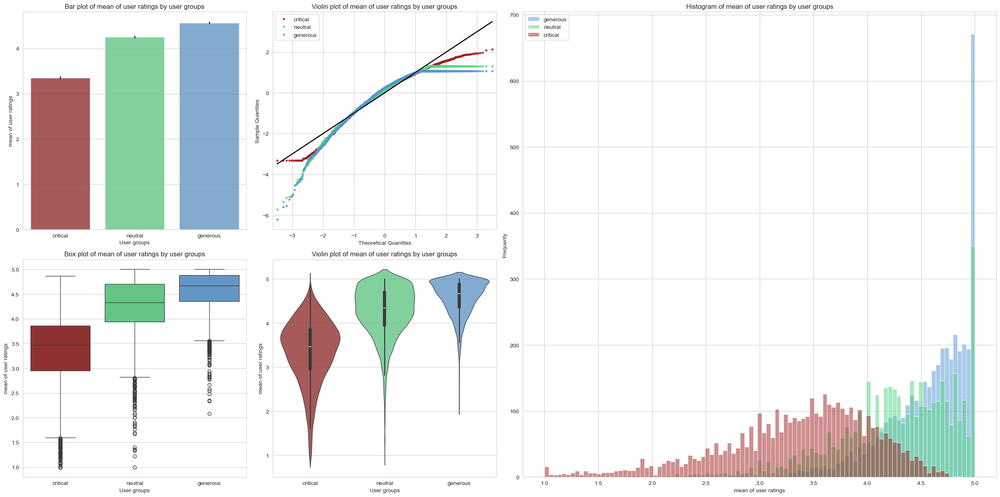

In [32]:
distribution_visualizer.plot_stats("rating_mean", show=True)

For the next following analyses, we will be using the bar plot, box plot, violin plot, histogram, and QQ plot to compare different statistics along central tendency, spread, skewness, density, and normality. 
We begin by interpreting average ratings along these different graphs. The bar plot shows critical users having the lowest mean rating with neutral users in the middle and generous users clustered together in maximum rating. As such, this shows our grouping definitions of critical versus generous correspond to behavioral differences. 
As for the box and violin plot, we can see generous users having rather compressed distributions with most of such users clustered at the high end, neutral users showing a slightly wider spread with still a decently high skew, and critical users showing an evenly distribution range of ratings with an even wider spread. 
The QQ plot supports the results displayed in the other graphs as we can clearly see generous and neutral users deviating sharply from the diagonal while critical users are still in the general vicinity of the diagonal line. Knowing this helps justify modeling decisions later on, as normality may hold better for some groups rather than others. 

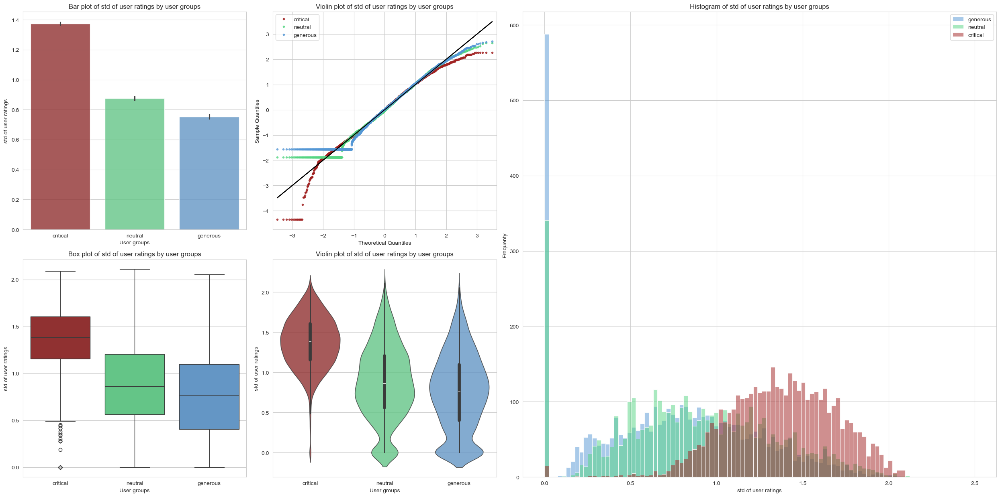

In [33]:
distribution_visualizer.plot_stats("rating_std", show=True)

As for the standard deviation of ratings, these plots tell us how consistently each user assigns ratings. Thus,the standard deviation tells us how much each specific user varies their ratings across differing restaurants. 
To start, the bar plot shows critical users having the highest average rating std which means they change their ratings more widely across restaurants. Furthermore, critical users have a wider distribution with many users showing moderate to high variability whereas neutral users show a tight cluster in the mid ranges and generous users having the narrowest distribution which indicates them tending to assign similar ratings across restaurants. 
The Histogram is interesting as it displays a strong spike where the standard deviation is 0. This implies many neutral and generous users gave the same rating to 	every restaurant they reviewed, e.g. generous users consistently giving 5 star reviews. This is different from critical users whose distribution starts farther on the right of the histogram. 
Lastly, the QQ plot shows that none of the groups particularly show a normal distribution but generous and neutral users are closer compared to critical users. 
How this ties into our hypothesis: generous users having a lower standard deviation which include that large number of users with std equalling 0, imply they tend to consistently give higher ratings and rarely adjust their evaluations. This greatly supports our hypothesis that generous reviewers give consistently higher ratings while seldom adjusting their evaluations, fitting our prediction that generous users would have higher average ratings and shorter, more positive reviews. 

### Number of Reviews

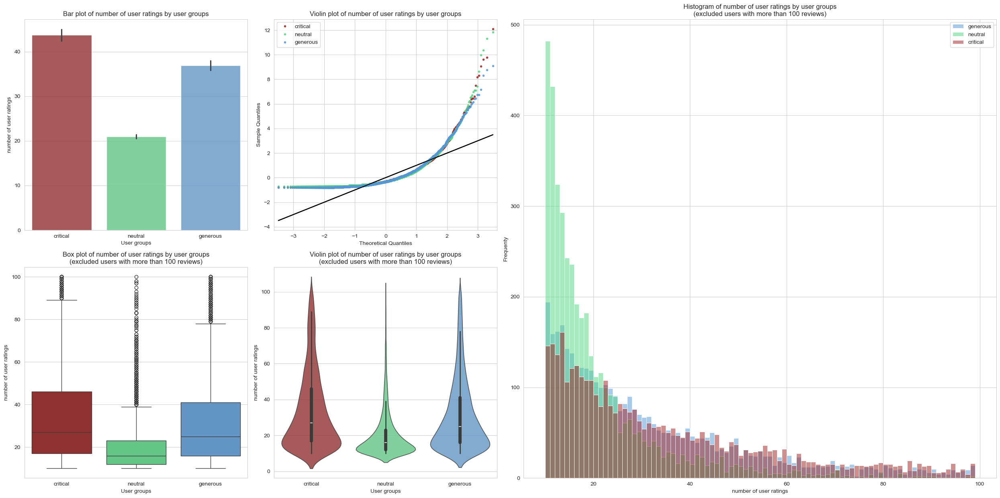

In [34]:
distribution_visualizer.plot_stats("num_reviews", show=True)

By visualizing the number of reviews, it will directly show us review activity which is evidence for or against our hypothesis that predicts generous users having less frequent reviews than “neutral users” and critical users having more frequent reviews than “neutral users”. However, as elucidated below, the visualization of the data shows we were incorrect / only partially correct. 
The bar plot confirms high engagement in critical users and unexpected high engagement in generous users which also bolsters the bar graph we did in the analysis overview section.
Box and violin plots show a high median with wide distributions, generous users have moderate activity above neutral, and neutral users have a tight clustering where the minimum is. 
Histogram shows neutral users having a sharp drop after 10 reviews while generous and critical users extend far into the higher ranges. Moreover, there is large spike at 10 reviews because we only included users with more than 10 reviews and many users who are neutral sit exactly at this minimum threshold which explains why they consistently show lower means and smaller spread with fewer high-activity outliers in the first place. This supports the neutral users as the baseline group. 
As for the QQ plot, all groups deviate away from the diagonal line. 
Thus, our hypothesis is half correct since although critical users are significantly more active than neutral users, generous users post more reviews than neutral users, not less. This perhaps insinuates generous users enjoy leaving positive feedback and therefore contribute more frequently than we initially anticipated. So perhaps we can infer critical users are highly engaged due to strong negative reactions whereas generous users are highly engaged due to enthusiasm for sharing positive experiences. 


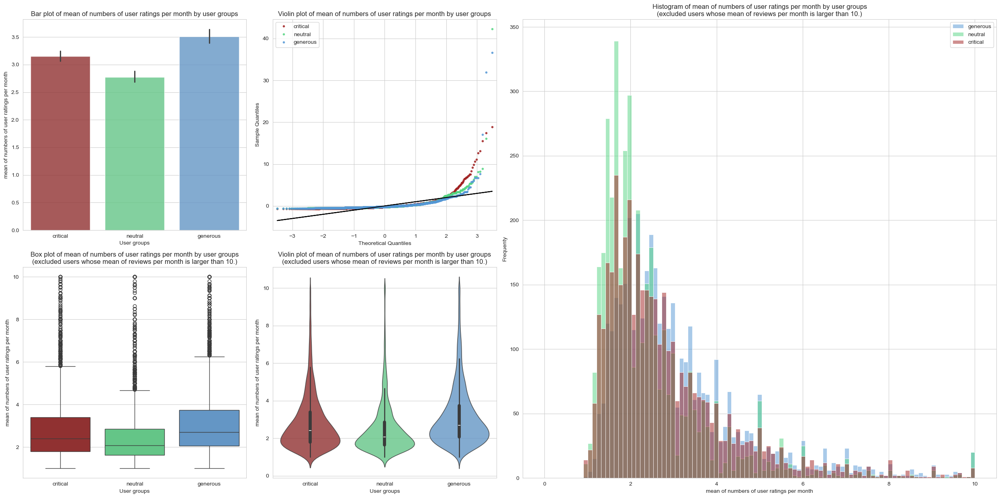

In [35]:
distribution_visualizer.plot_stats("num_reviews_monthly_mean", show=True)

We then split reviews into monthly intervals to see if any changes arise to the data. Regardless, the bar, box, and violin plots show that generous and critical users still leave reviews more frequently than neutral users. The histogram also displays a right skewed distribution for all groups with neutral users at the lower monthly frequencies. This matches what we saw in the previous analyses on review activity except for the difference that generous users actually review more frequently than critical users, perhaps insinuating that critical users review a lot overall but their activity is more spread out whereas generous users less than but more consistently on a month to month basis. 

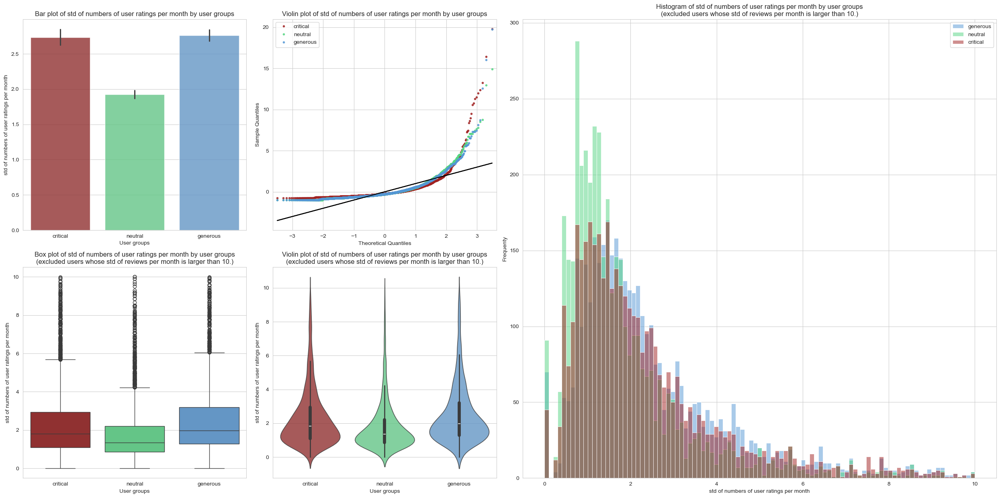

In [36]:
distribution_visualizer.plot_stats("num_reviews_monthly_std", show=True)

From noticing that difference in monthly count of reviews between generous users and critical users, we decided to also assess its standard deviation, allowing us to again compare how consistently each user posts reviews. Bar, box, and violin plot shows critical and generous users having higher monthly variability than neutral users which imply neutral users review steadily at a lower rate. Histogram shows a right skewed pattern for all groups. QQ plot shows critical users deviating more from normality which reflects the notion that critical users have bursts of monthly activity. 

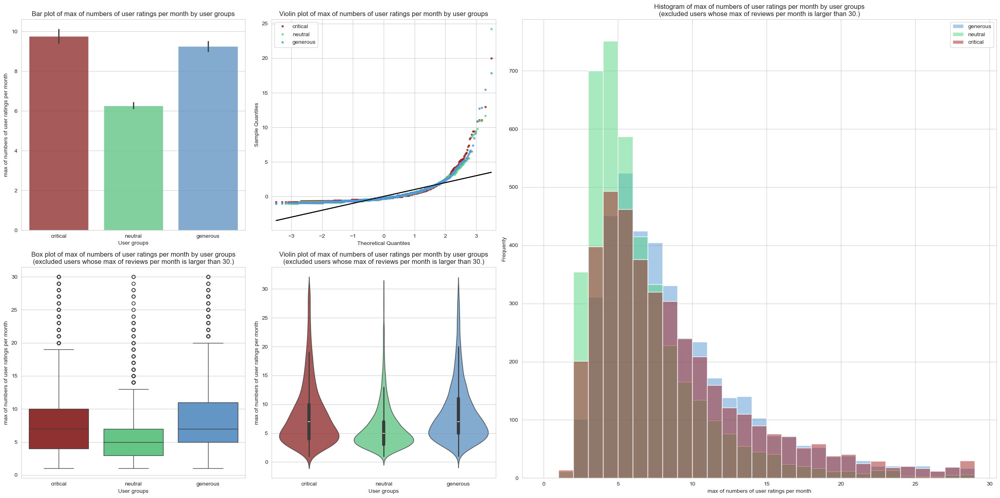

In [37]:
distribution_visualizer.plot_stats("num_reviews_monthly_max", show=True)

Then, the graphs above were plotted to assess the intensity in which a user writes reviews within a single month. The bar, box, and violin plots all show critical and generous users reaching higher monthly peaks than neutral users with neutral users having the lowest maxima and narrowest spread. As per usual, the histogram shows a strong right skew for all groups with critical and generous users extending into high activity months. Thus, these graphs support previous conclusions on reviewing behavior regarding generous users rating more on average per month with critical users rating less frequently but more intensely. Further takeaways and summaries will be embellished in sections near the bottom of the file. 

### Review Length

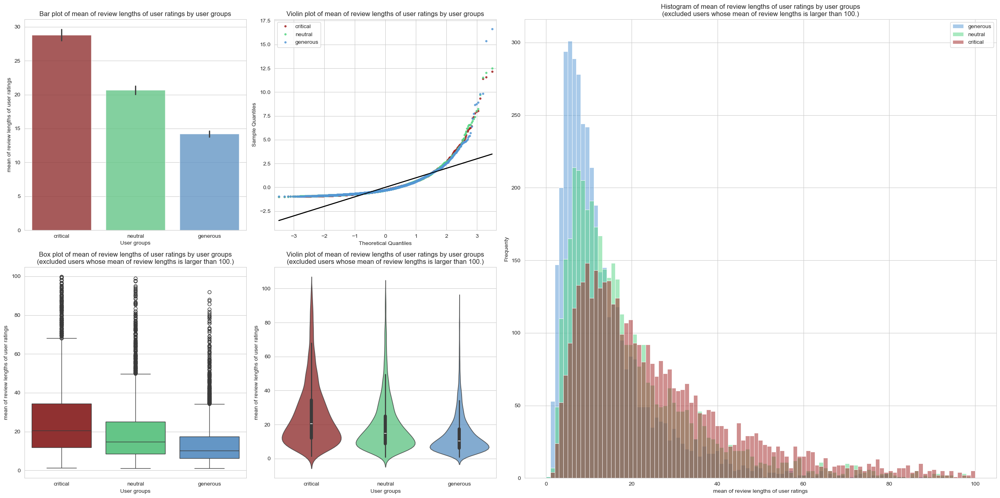

In [38]:
distribution_visualizer.plot_stats("review_length_mean", show=True)

Our hypothesis predicts critical users writing longer reviews with generous users writing shorter reviews so this plot of average review length per user group allows us to assess that. The bar, box, and violin plots clearly show critical users writing long reviews, neutral users writing medium length reviews, and generous users writing short reviews. The histogram implies all groups are heavily right skewed as per usual with a bunch of short reviews and few long ones that are heavily dominated by critical users. Thus, it also resembles a chi-square distribution with high frequency near 0 and a long right tail of increasingly long reviews. 

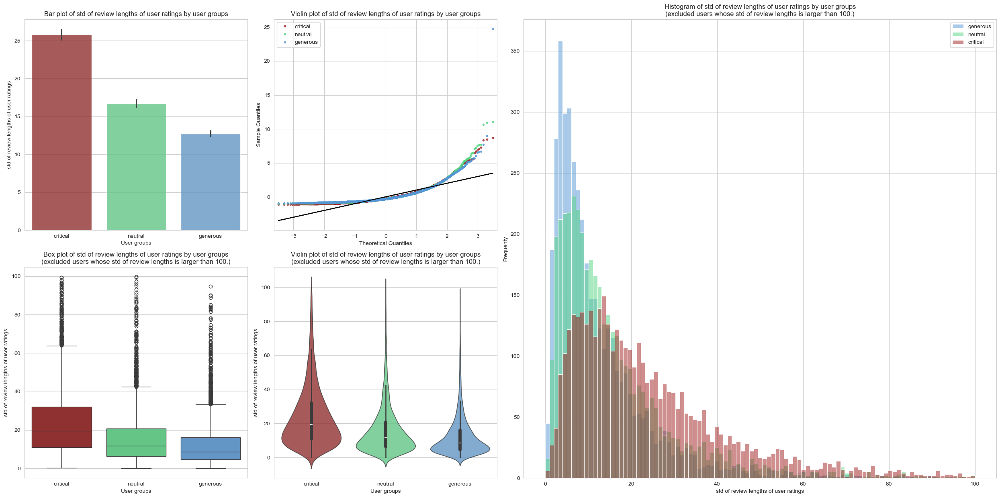

In [39]:
distribution_visualizer.plot_stats("review_length_std", show=True)

Analyzing the standard deviation of the review lengths will elicit how consistently they write their reviews with that particular length. Meaning we’ll be able to discern whether some groups fluctuate between short and long reviews more than others. Bar, box, and violin plots show critical users having the largest variation in review length as they swing between short and long reviews. Generous users have the smallest variation which matches what we’ve seen so far in previous plots since they tend to write shorter reviews. Overall, critical users show the most variability meaning they not only write longer reviews on average but also go back and forth between different lengths which reinforces the idea they put more time/effort into reviews when they feel strongly. Generous users show the least variability which aligns with the hypothesis that this group writes short consistent reviews. The overall right skewed chi squared distribution matches what we expect when most reviews are short with a minority of users occasionally producing long ones. 


### Number of Cities

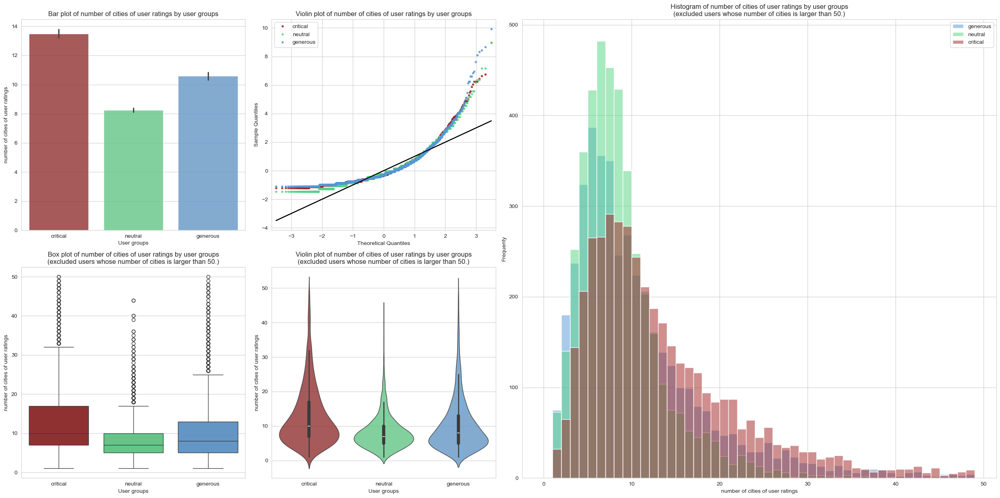

In [40]:
distribution_visualizer.plot_stats("num_cities", show=True)

This plot was included to see whether visiting more places had an affect on review activity. For instance, if critical and generous users travel more, then by default, they have more opportunities to write reviews. The plot shows critical and generous users have visited more cities than neutral users on average. The bar plot shows higher means. The box and violin plots have higher medians and broader spread. And the histogram is of course, right skewed with most users rating only a few cities but a smaller number of heavy travelers pushing 40 and above(we excluded users who rated more than 50 cities since they’re extreme outliers who would distort the scale of the histogram, inflate the variance, and make comparisons harder to interpret). Thus this plot gives a new perspective on how and why critical and generous users are more active overall, as they explore more locations. 

### Sentiment of Reviews

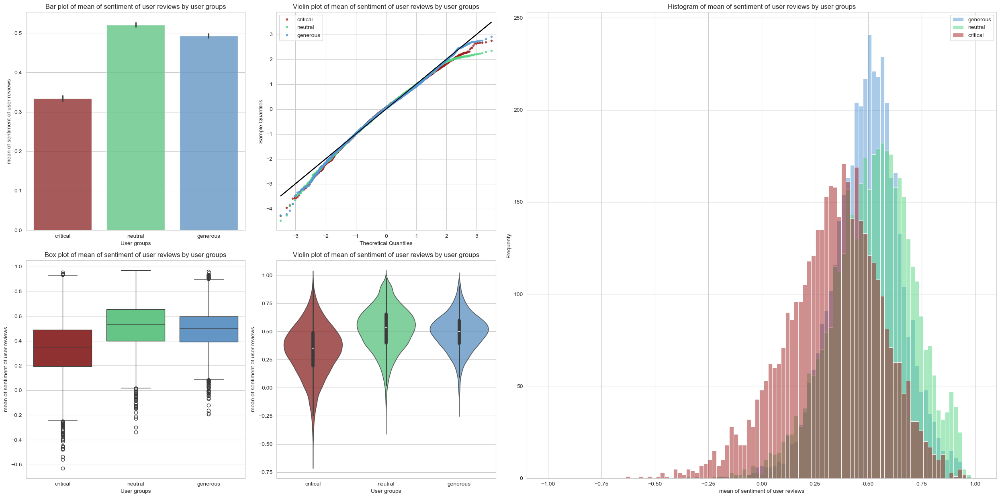

In [41]:
distribution_visualizer.plot_stats("sentiment_mean", show=True)

Now we want to see whether and how users in different rating groups differ in the emotional tone of their written reviews. To no one’s surprise, critical users have the lowest average sentiment. However, although generous users are more positive than critical users, they are slightly less positive than neutral users. This is shown in the bar and violin plot with different central tendencies across the groups and the histogram with critical reviews shifted left, neutral reviews most positive, and generous reviews  slightly right of critical reviews. Now to address why generous users score lower than neutral users despite being generous raters, we can extract from the conclusions of the plots above and assert generous users leave shorter reviews on average and shorter reviews tend to contain fewer positive adjectives which is why sentiment models score shorter reviews less positively. Longer reviews in contrast may contain more descriptive positive language unlike generous reviews. This shows text sentiment and star ratings do not always align and that review length influences sentiment scoring.   

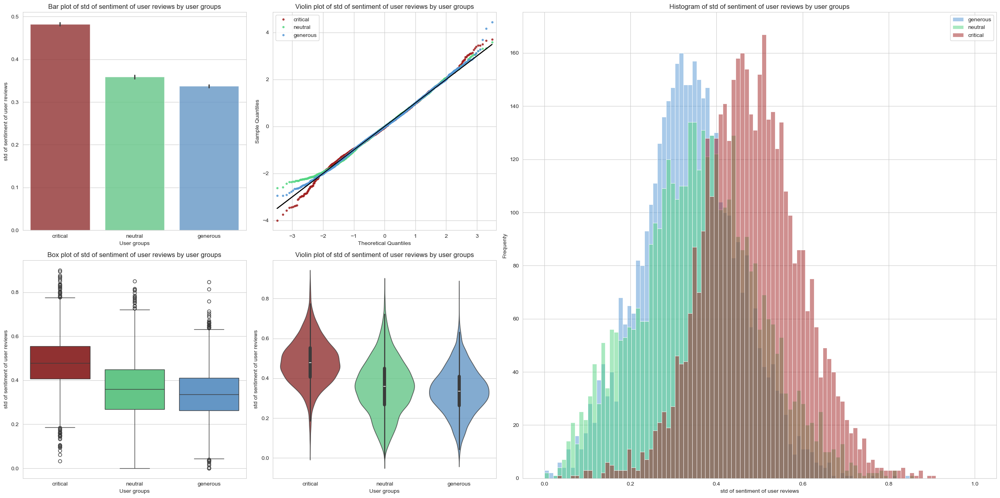

In [42]:
distribution_visualizer.plot_stats("sentiment_std", show=True)

Plotting the standard deviation of the sentiment allows us to understand whether different user groups show different consistency in emotional tone in their reviews. For once, the QQ plot actually shows the standard deviation of sentiment having a normal-like distribution which implies variation behaves fairly regular across users. However, critical users do have higher sentiment variability than neutral and generous users. Neutral and generous users have tight, lower-variance distributions that show more consistent sentiment in their writing. The takeaway is that critical users aren’t only more negative but are less consistent in how negative or positive they write. 

### User Activity Over Time

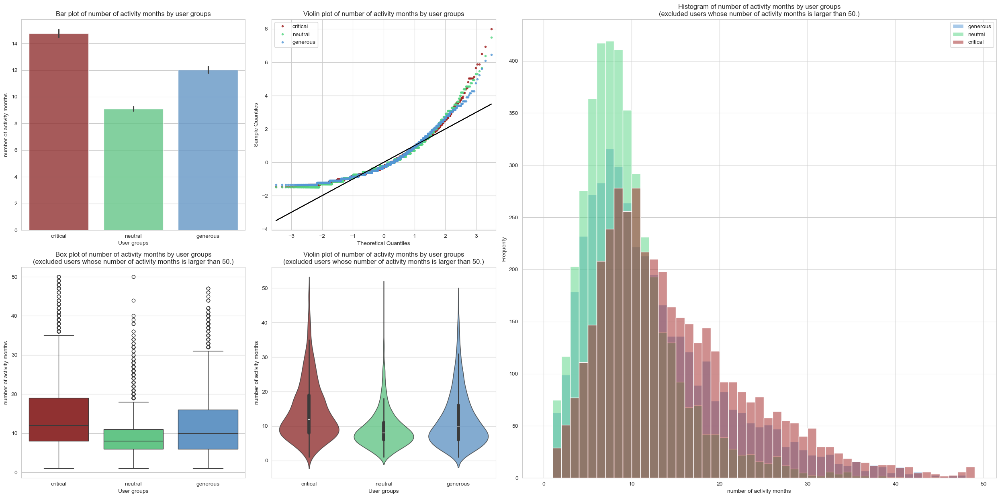

In [43]:
distribution_visualizer.plot_stats("activity_months", show=True)

We included this plot to examine whether different user groups remain active for different lengths of time which relates directly to review frequency and long term engagement. The bar, violin, and histogram plots show critical and generous users having more active months than neutral users. Like with some plots above, we removed users with more than 50 active months to make analysis easier. The results here that show critical and generous users having larger active months compared to neutral users correspond with the number of reviews each group has. 

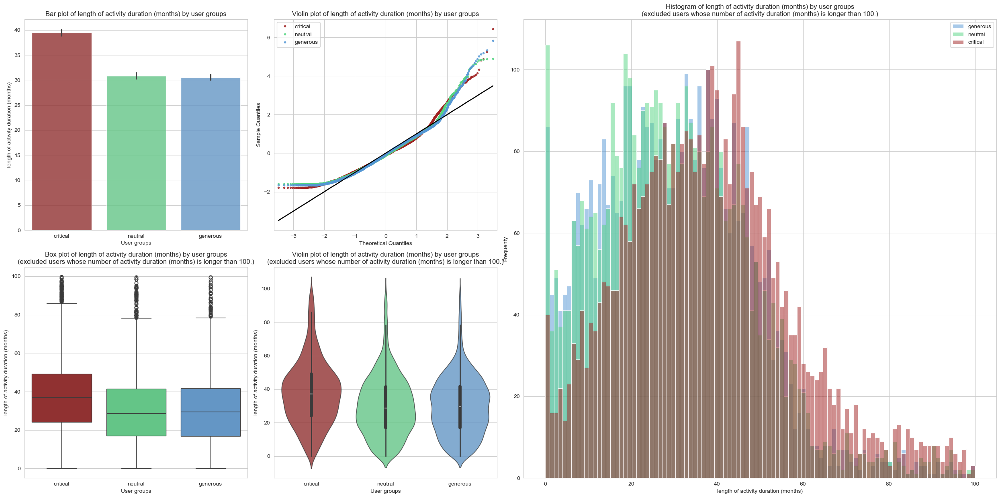

In [44]:
distribution_visualizer.plot_stats("activity_duration", show=True)

We included this plot to take on a new perspective on user activity. We want to investigate how long users remain active overall rather than just how many months they post in–we want to know the total span of time between their first and last reviews. The bar plot nicely displays critical users having the largest average activity duration by quite a margin. It’s pretty significant here to see critical users having the longest activity duration because it indicates they’ve been consistently active for a longer period of time than neutral and generous users. Neutral and generous users actually have pretty similar duration distributions which suggest their difference in behavior isn’t particularly driven by long time critical users who have openly stated their opinion against the norm and sustained that over time. Again to mention, users with more than 100 months of duration were excluded to remove outliers for easier analysis. The takeaway is that the data suggest that unique features of critical users come from their long activity but the unique features of generous users come from behavior in and of themselves. 

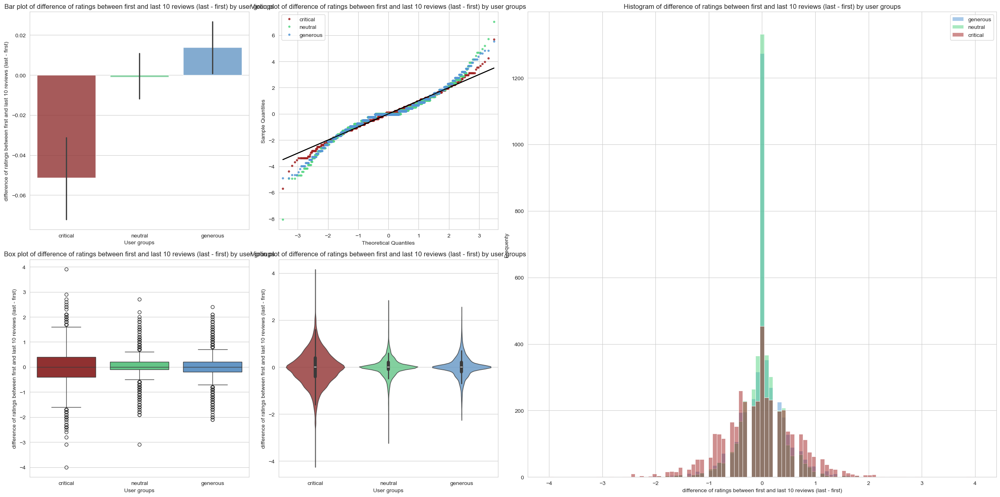

In [45]:
distribution_visualizer.plot_stats("activity_rating_diff", show=True)

We included this plot to measure how user’s ratings behavior changes over time by comparing their first 10 reviews to the last 10 which helps us identify which groups became more critical, more generous, or stayed consistent. The bar plot shows critical users decreasing their ratings over time as if they weren’t critical enough to begin with, generous users increasing their ratings over time, and neutral users remaining near zero which signifies stable behavior. 
The QQ plot shows all groups following a similar shape confirming differences are due to perhaps behavior shift instead of distribution skew. The histogram has differences of the user groups centered around zero with slight changes in distribution shifts amongst user groups. Critical users are slightly more spread in the negative direction and generous users show a miniscule shift toward the positive direction. The violin plot supports this, showing critical users skewing negative, generous users skewing positive and neural users remaining balanced. Thus, we can conclude that critical users become increasingly more critical as they continue reviewing while generous users become more and more generous over time. Neutral users stay consistent as the control group it should be. 

### Diversity of Words in Review

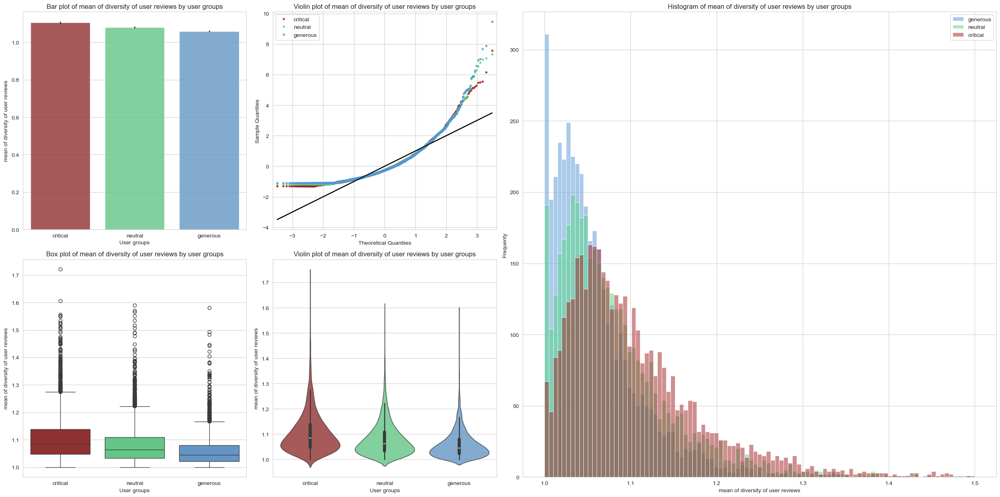

In [46]:
distribution_visualizer.plot_stats("diversity_mean", show=True)

Including this plot allows us to assess how groups use language differently. The bar plot so far supports the conclusions we made above so far with critical users having the highest average diversity while neutral users have lower and generous users having the lowest. The histogram has generous users clustered around low diversity values while critical users as always have that long right tail which implies reviews with more intricate / unique word play. The box plot shows critical users having a higher median and larger spread than other groups. The violin plot confirms critical users consistently use unique words more often while generous users show the tightest lowest distribution. Nevertheless, it remains the same that generous users tend to have shorter reviews which definitely impact the diversity exemplified in this plot. 

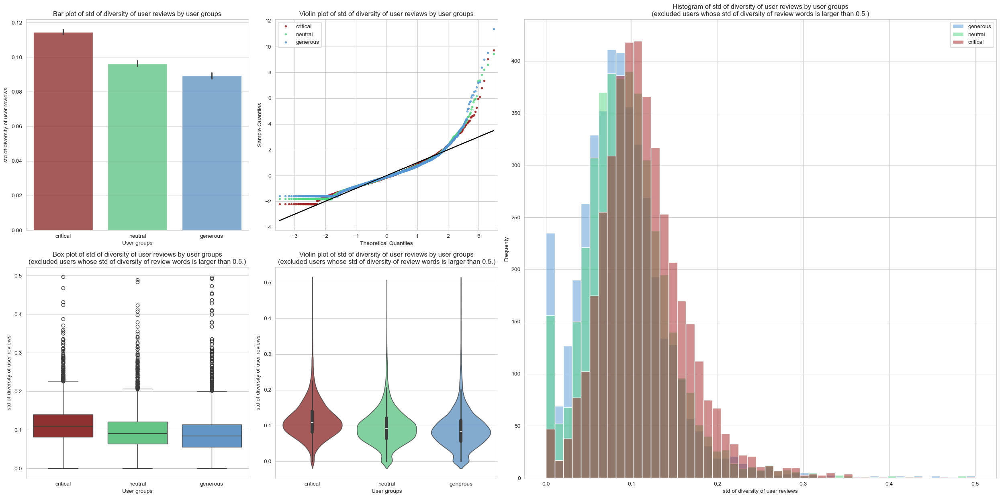

In [47]:
distribution_visualizer.plot_stats("diversity_std", show=True)

Then we wanted to know how consistent each user group is with their use of unique words. After all, we’ve applied standard deviation to all of our previous metrics and sometimes it displays enlightening results. However, this one simply corresponds to the diversity mean plot right above. The bar plot shows critical users having the highest variation in vocabulary diversity while generous users have the lowest. The QQ plot has nothing significant as it continues to display non-normality. However, significance does come from the fact that they all follow a similar curve bolstering the foundation that their behavioral differences are real instead of statistical artifacts. Histogram shows critical users having a wider spread toward higher variation while generous users cluster tightly around lower variance. Box and Violin plot follow the same trends as with the mean diversity plot above. Thus, overall critical users vary the most in how many unique words they use per review while generous users vary the least, matching the notion that they write shorter and simpler straightforward reviews. 

### Pair Relationships

In [48]:
class PairVisualizer():
    def __init__(self, stats):
        self.stats = stats

    def plot_rating_mean_review_length_mean(self):
        filtered_stats = self.stats[self.stats["review_length_mean"] <= 100]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name_x": "rating_mean",
            "name_y": "review_length_mean",
            "desc_x": "mean of ratings",
            "desc_y": "mean of review lengths",
            "ratio_range": [0, 20],
            "bins": np.linspace(0, 20, 50),
            "opt_ratio_desc": "excluded users whose ratio is larger than 2.0.",
            "opt_scatter_desc": "excluded users whose mean of review length is larger than 100."
        }

        return config

    def plot_num_reviews_num_cities(self):
        filtered_stats = self.stats[np.logical_and(self.stats["num_cities"] <= 50, self.stats["num_reviews"] <= 200)]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name_x": "num_reviews",
            "name_y": "num_cities",
            "desc_x": "number of user reviews",
            "desc_y": "number of cities of restaurants a user rated",
            "ratio_range": [0, 1.0],
            "bins": np.linspace(0, 1.0, 50),
            "opt_ratio_desc": None,
            "opt_scatter_desc": "excluded users whose number of cities is larger than 50 or number of reviews is larger than 200."
        }

        return config

    def plot_rating_mean_sentiment_mean(self):
        filtered_stats = self.stats

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name_x": "rating_mean",
            "name_y": "sentiment_mean",
            "desc_x": "mean of user ratings",
            "desc_y": "mean of review sentiment",
            "ratio_range": [-0.2, 0.2],
            "bins": np.linspace(-0.2, 0.2, 50),
            "opt_ratio_desc": "excluded users whose ratio is outside of [-0.2, 0.2]",
            "opt_scatter_desc": None
        }

        return config

    def plot_rating_std_sentiment_std(self):
        filtered_stats = self.stats

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name_x": "rating_std",
            "name_y": "sentiment_std",
            "desc_x": "std of user ratings",
            "desc_y": "std of review sentiment",
            "ratio_range": [0, 1.0],
            "bins": np.linspace(0, 1.0, 50),
            "opt_ratio_desc": "excluded users whose ratio is outside of [0, 1.0]",
            "opt_scatter_desc": None
        }

        return config

    def plot_activity_months_activity_duration(self):
        filtered_stats = self.stats[np.logical_and(self.stats["activity_months"] <= 50, self.stats["activity_duration"] <= 150)]

        config = {
            "stats": self.stats,
            "filtered_stats": filtered_stats,
            "name_x": "activity_months",
            "name_y": "activity_duration",
            "desc_x": "number of active months of user",
            "desc_y": "length of active duration of user (months)",
            "ratio_range": [0, 10],
            "bins": np.linspace(0, 10.0, 50),
            "opt_ratio_desc": None,
            "opt_scatter_desc": "excluded users whose number of activity month is larger than 50 or activei duration of user is larger than 150."
        }

        return config

    def plot_stats(self, name_x, name_y, show=False):
        method_name = f"plot_{name_x}_{name_y}"
        config = getattr(self, method_name)()
        plot_pair(config, show)

    def plot_all_stats(self):
        with open(f"{results_path}/pairs.txt", "r") as f:
            stats_list = [p.split(",") for p in f.read().split()]

        for stats in stats_list:
            print(f"Plotting {stats[0]} vs {stats[1]} statistics")
            self.plot_stats(*stats)

In [49]:
pair_visualizer = PairVisualizer(stats)

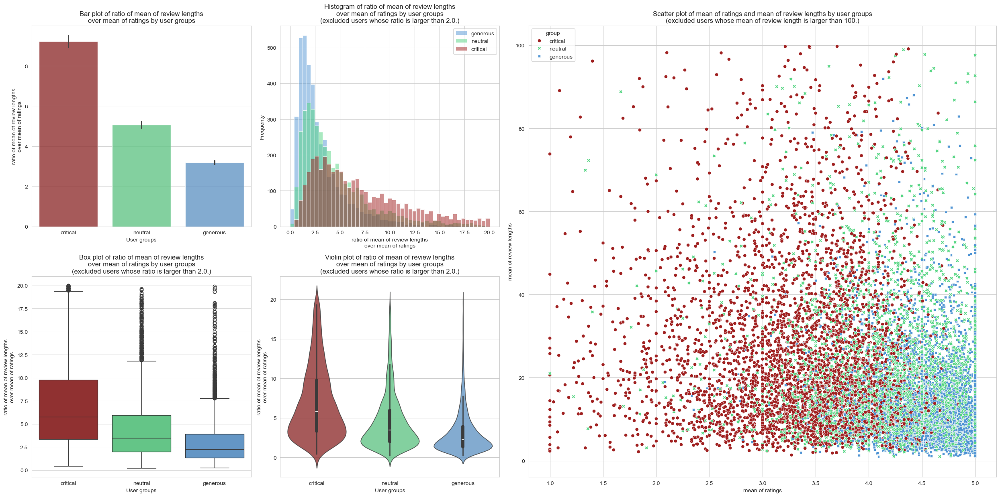

In [50]:
pair_visualizer.plot_stats("rating_mean", "review_length_mean", show=True)

We chose this pair to examine whether a user’s average ratings relate to how long their reviews are. The ratio version of bar, histogram, box, and violin plots show critical users having a higher review length per review ratio with the exclusion of users whose ratio is larger is 2.0 for simplifying analysis purposes. The scatter plot (which excludes users with average review lengths greater than 100) shows critical users clustering at lowering ratings with longer reviews whereas generous users cluster at higher ratings with shorter reviews. Thus, rating_mean and review_length_mean strongly differentiate user types and directly support the part of our hypothesis that predicts critical users writing lower rated reviews while generous users write shorter higher rated ones.

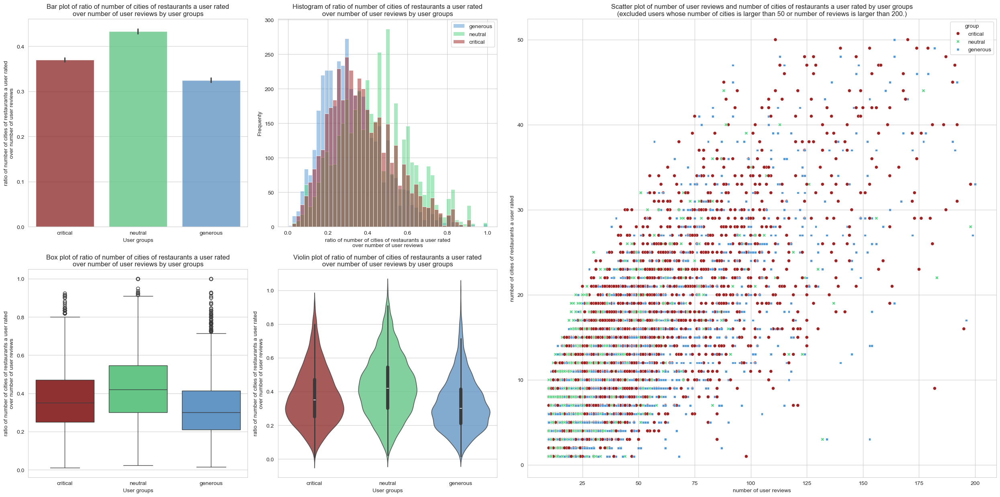

In [51]:
pair_visualizer.plot_stats("num_reviews", "num_cities", show=True)

This pair normalizes how widely users travel by comparing the number of cities visited to the total reviews. Users with more cities relative to reviews are thus more exploratory in nature. Neutral users show the highest ratios in the bar/violin plots which indicate that they visit and rate restaurants across more cities while critical and generous users funnel their reviews into fewer cities. Furthermore, the plots show critical and generous users clustering at lower city counts which suggest they rate mostly around their home city compared to neutral users. The normalization here provides a new context since previous plots and analyses were subject to differences caused by sheer volume, contradicting some previous analyses above that critical and generous users were more active overall traveling place to place. 

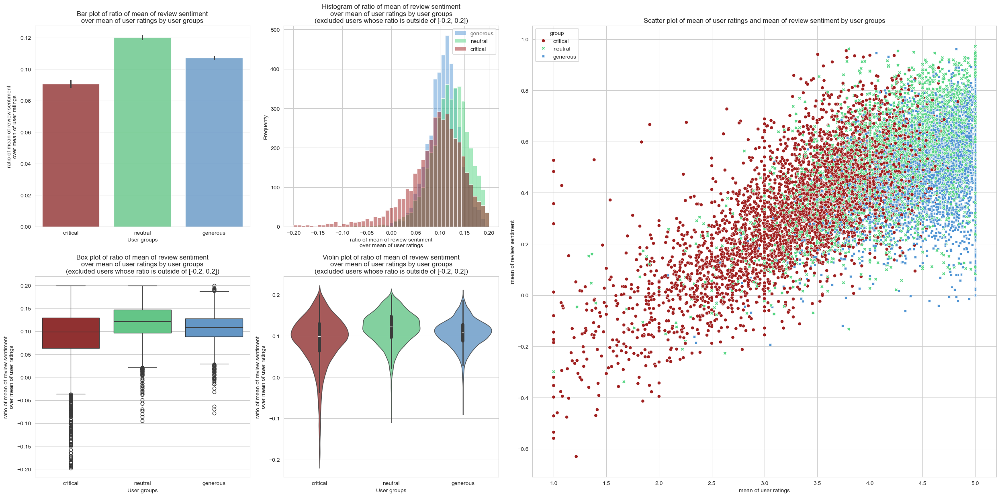

In [52]:
pair_visualizer.plot_stats("rating_mean", "sentiment_mean", show=True)

Here, this pair examines the correlations between average sentiment and average rating. Finding correlations with these pair plots give us further insight on further models below. The bar, histogram, and violin plot show neutral users having the highest ratio of sentiment to rating which means they give higher ratings even with written sentiment less positive. In contrast it’s no surprise that critical and generous users display lower ratios which indicates that their star rating more closely resembles the sentiment of their text with critical users staying negative in rating and sentiment while generous users remain consistently positive in rating and sentiment. The scatterplot nicely shows critical users clustered in the lower left, generous users clustered in the upper right, and neutral users sitting in between but shifted upward in ratings relative to sentiment which shows this sort of systematic rating inflation. 

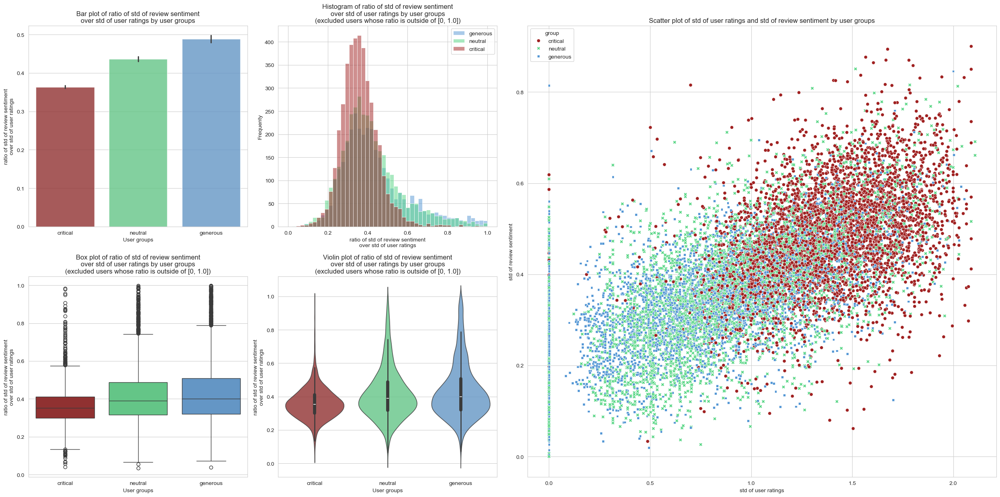

In [53]:
pair_visualizer.plot_stats("rating_std", "sentiment_std", show=True)

Now we observe the correlation between how inconsistent users are in their ratings and how inconsistent they are in the emotional tone of their reviews. The bar, histogram, and violin show generous users having the lowest variation in ratings but the highest variation in sentiment. This implies generous users typically give consistently high ratings even if their writing tone shifts from positive to negative. In contrast, neutral users are in the middle, and critical users display higher rating variability relative to sentiment variability which is good as it implies it’s more likely their reviews exhibit how they actually feel rather than sporadic ratings being a product of their behavioral habits. Anyways, as for the scatterplot, critical users appear higher on the rating-std axis which means their rating fluctuates greater than the tone of their text. Generous users show lower on the rating-std but spread upward in sentiment-std which show stable behavior despite varied textual tone. And of course, the neutral users fill in the intermediate region with moderate variability in both ratings and sentiment. 

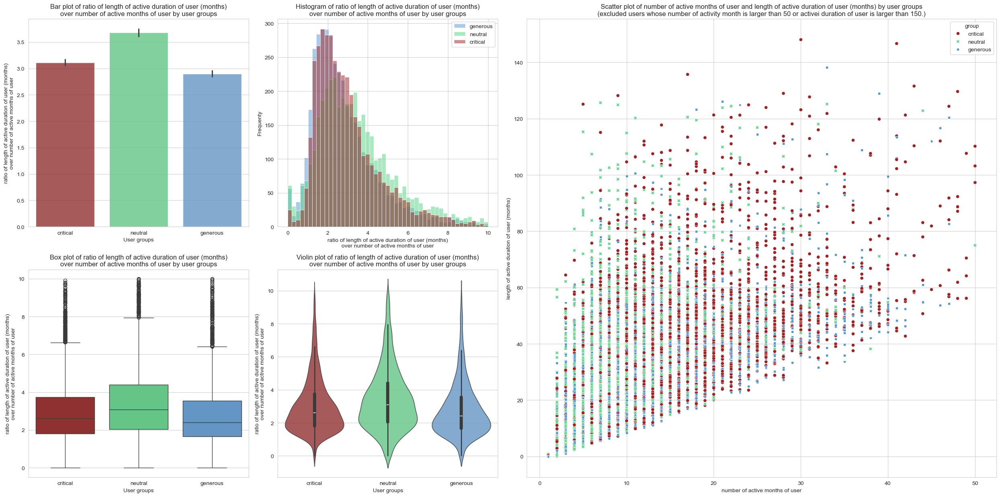

In [54]:
pair_visualizer.plot_stats("activity_months", "activity_duration", show=True)

Now we compare / assess correlation between the amount of months a user was actively posting reviews and the total timespan they wrote reviews. A higher ratio would suggest activity spread out over a 
long period, while a lower ratio indicates more concentrated bursts of usage. The bar and violin plot show neutral users having the highest activity duration relative to number of active months which 
makes sense as they tend to review across longer review time windows with less frequent activity. On the other hand, critical and generous users have lower ratios suggesting their reviews are clustered 
within bursts of time. All in all, the graphs here show neutral users behaving more like long term steady reviewers while critical and generous users exhibit burst like activity patterns by reviewing 
within shorter spans of time. 

### Text Analysis

In [55]:
def plot_wordcloude(texts, group, show):
    wordcloud = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(texts)

    plt.figure()
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud for {group} users")
    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/texts", exist_ok=True)
        plt.savefig(f"{results_path}/texts/wordcloude_{group}.png")
        plt.close()

def plot_wordclouds(combined, show=False):
    groups = np.unique(combined["group"].values)

    for group in groups:
        texts = " ".join(combined[combined["group"] == group]["text"].values)
        plot_wordcloude(texts, group, show)

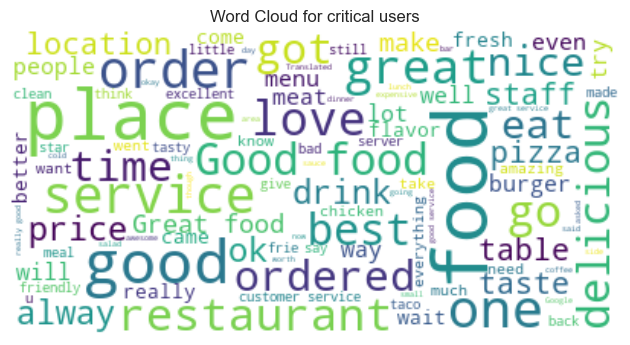

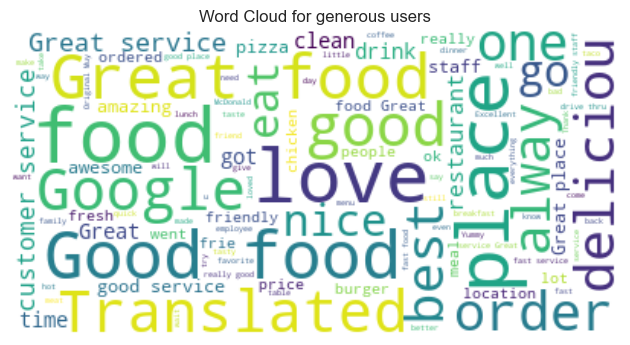

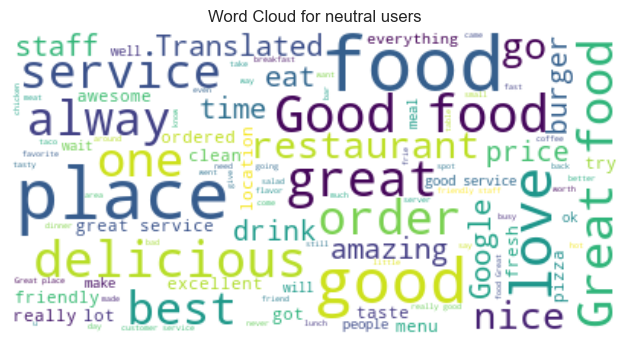

In [56]:
plot_wordclouds(combined, show=True)

These word clouds greatly give us the capacity to visualize the frequency of words used in each user group and allow us to gain a new perspective on the results of plotting sentiment. For example, there’s no particular exhibition of negative words that are visibly large in the word cloud for critical users despite this group typically writing longer reviews in general. Regardless, all word clouds align with the distribution seen in earlier plots like sentiment_mean where neutral and generous users show the most positive sentiment while critical users–although still showing generally positive sentiment–show slightly less positive sentiment. Next, the decently large word “Translated” isn’t the word used in the review itself but rather an indication of machine translation which typically flattens hyperbolic patterns in language–reducing emotional subtlety. Thus, the generous user group might benefit from this as generic emotional words like good and great amplify their sentiment scores. Furthermore, since Translated shows up most in the generous group, it allows us to question the demographic of people who deviate from the norm and rate things higher–e.g. tourists. 

In [57]:
def find_most_common_words(texts, num_words):
    texts = re.sub("[^0-9A-Za-z]", " ", texts).lower()
    wordlist = set(stopwords.words("english"))
    tokens = [t for t in texts.split() if t not in wordlist]

    unique, counts = np.unique(tokens, return_counts=True)
    indices = np.argsort(counts)[::-1][:num_words]
    return unique[indices]

def create_count_dict(texts, num_reviews):
    texts = re.sub("[^0-9A-Za-z]", " ", texts).lower()
    wordlist = set(stopwords.words("english"))
    tokens = [t for t in texts.split() if t not in wordlist]

    unique, counts = np.unique(tokens, return_counts=True)

    word2count = {word:count / num_reviews for word, count in zip(unique, counts)}
    return word2count

def plot_most_common_words_by_group(combined, show=False):
    groups = np.unique(combined["group"].values)

    num_words = 20
    most_common = find_most_common_words(" ".join(combined["text"].values), num_words)

    counts = []
    for group in groups:
        group_reviews = combined[combined["group"] == group]
        texts = " ".join(group_reviews["text"].values)
        count_dict = create_count_dict(texts, group_reviews.shape[0])
        counts += [(word, count_dict[word], group) for word in most_common]

    df = pd.DataFrame(counts, columns=["word", "count", "group"])

    sns.set_style("whitegrid")
    plt.figure(figsize=(15, 10))
    sns.barplot(df, x="count", y="word", hue="group", palette=palette, order=most_common, hue_order=order, alpha=0.8)

    plt.title(f"Most commond words by user group")
    plt.xlabel("Frequency divided by total number of reviews per group")
    plt.ylabel("Most common words")
    plt.tight_layout()

    if show:
        plt.show()
    else:
        os.makedirs(f"{results_path}/texts", exist_ok=True)
        plt.savefig(f"{results_path}/texts/most_common.png")
        plt.close()

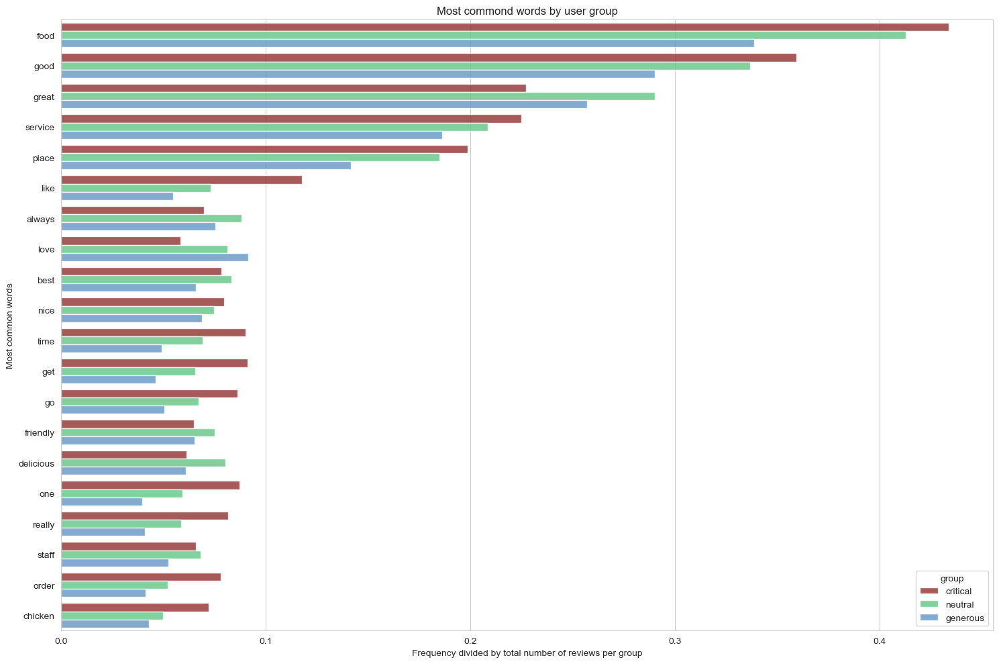

In [58]:
plot_most_common_words_by_group(combined, show=True)

This bar chart allows us to compare the frequency of the most common words across critical, neutral, and generous users. However, something to note is that these counts aren’t normalized so it’s important to take into account that groups that write longer reviews–critical users in particular–naturally show higher total word usage. This bar chart shows generous users using emotionally loaded words more frequently than critical users like great, love, always, and delicious. Since their reviews are shorter as assessed from previous analyses above, each positive word contributes more to the proportion of the total text which boosts their sentiment score. As for critical users, grouping together their most frequent words show functional words like order, service, time, staff, and place. This implies the analytical functional nature of reviews coupled with longer reviews in general probably explain their lower sentiment score even with large counts of words like good and great. Thus, the high polarity nature of generous reviews coupled with their shorter reviews boost their sentiment score higher while the low-polarity functional nature of critical reviews coupled with their longer reviews decrease their sentiment score. 

## Ethics

## Ethics 

[![Deon badge](https://img.shields.io/badge/ethics%20checklist-deon-brightgreen.svg?style=popout-square)](http://deon.drivendata.org/)

For the formatted Ethics checklist, please see the ethics checklist in [**ethics.md**](./Ethics.md) in this repo.


## Team Expectations 

* Communication

    * We will communicate primarily through text message, with backup communication via email for important updates
    * Team members are expected to respond within 24 hours to messages unless otherwise stated
    * We will meet once a week (in person or on Zoom) to check progress and plan next steps
* Tone

    * We will use an expected tone of "blunt but polite" to express our opinions but in a respectful way
    * Our feedback will be constructive and everyone's ideas will be heard before making  major decisions
* Decision Making

    * Decisions will be made by majority vote, but for smaller choices, the decisions can be made by whoever is working on that section
    * if a decision has to be made in a short time frame and a teammate is non-responsive, then the rest of the team is given the ability to decide and proceed
* Tasks

    * Each member will contribute equally in effort as everyone will do a bit of everything
    * Tasks will be tracked by communication in our group chat and each person will be honest about fulfilling their duties and responsibilities
    * Members are expected to complete tasks by agreed deadlines and communicate early if they anticipate delays
* Plan

    * We will use our project timeline proposal as an outline for our plan
    * We will update plan if changes are made and everyone will be informed of new plan
* Policies

    * If a team member realizes they are struggling to complete a task or meet a deadline, they should notify the group as soon as possible
    * The team will discuss the situation during the next meeting or via chat to decide the best course of action whether it may be reassigning portions of the task to other members temporarily or pairing the struggling member with another teammate for extra support
    * The struggling member is still expected to remain engaged in team discussions and contribute where possible, even if their main task is adjusted
    * If a member repeatedly struggles without communicating or following through on agreed plans, the group will first discuss it directly with them in a respectful and solution-oriented way
* Conflict

    * Conflicts will be discussed openly and respectfully during meetings
    * If issues persist, the team will notify the instructor by week 7 as outlined in the COGS108 policies
* Commitment:

    * By adding our names to this document, we confirm we have read the COGS108 Team Policies and agree to uphold these expectations for the duration of the project

## Project Timeline Proposal

| Meeting Date  | Meeting Time| Completed Before Meeting  | Discuss at Meeting |
|---|---|---|---|
| 10/29 |  4 PM | Read expectations, brainstorm topics/questions  | Decide baseline final project topic, discuss hypothesis; begin background research | 
| 11/05  |  4 PM |  Import & wrangle datasets | Discuss EDA | 
| 11/12  | 4 PM  |  EDA draft | Review EDA and discuss changes   |
| 11/19  | 4 PM  | Final EDA Draft| Discuss project check-ins and video   |
| 11/26  | 4 PM  | Rough final project draft | Discuss any final changes |
| 12/03  | 4 PM  | Completed final proejct| Discuss full project |